In [1]:
import pandas as pd
from pathlib import Path

dataset_path = Path("../data/raw/train-00000-of-00001.parquet")

if dataset_path.exists():
    print("Dataset file found!")
    print("File size:", round(dataset_path.stat().st_size / (1024 * 1024), 2), "MB")
else:
    print("Dataset file not found. Please check its location.")

Dataset file not found. Please check its location.


In [2]:
from pathlib import Path

print("Python is running from:")
print(Path.cwd())

print("\nFiles and folders here:")
for item in Path.cwd().iterdir():
    print(item.name)

Python is running from:
c:\Users\user\OneDrive\Desktop\Job_Skill_NLP\notebooks

Files and folders here:
job_skill_analysis.ipynb


In [3]:
from pathlib import Path

project_folder = Path.cwd().parent

print("Project folders:")
for item in project_folder.iterdir():
    print(item.name)

print("\nFiles inside data/raw:")
raw_folder = project_folder / "data" / "raw"

if raw_folder.exists():
    for item in raw_folder.iterdir():
        print(item.name)
else:
    print("The data/raw folder was not found.")

Project folders:
data
models
notebooks

Files inside data/raw:
train-00000-of-00001 (1).parquet


In [4]:
import pandas as pd
from pathlib import Path

dataset_path = Path("../data/raw/train-00000-of-00001 (1).parquet")

df = pd.read_parquet(dataset_path)

print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

Dataset loaded successfully!
Number of rows and columns: (1167, 5)

Column names:
['job_id', 'category', 'job_title', 'job_description', 'job_skill_set']

First 5 rows:


,job_id,category,job_title,job_description,job_skill_set
0,3902668440,HR,Sr Human Resource Generalist,SUMMARY\nTHE SR. HR GENERALIST PROVIDES HR EXP...,"['employee relations', 'talent acquisition', '..."
1,3905823748,HR,Human Resources Manager,BE PART OF A STELLAR TEAM AT YSB AS THE MANAGE...,"['Talent Acquisition', 'Employee Performance M..."
2,3905854799,HR,Director of Human Resources,OUR CLIENT IS A THRIVING ORGANIZATION OFFERING...,"['Human Resources Management', 'Recruitment', ..."
3,3905834061,HR,Chief Human Resources Officer,JOB TITLE: CHIEF HUMAN RESOURCES OFFICER (CHRO...,"['talent management', 'organizational developm..."
4,3906250451,HR,Human Resources Generalist (Hybrid Role),DESCRIPTION\n\n WHO WE ARE \n\nAVI-SPL IS A DI...,"['Microsoft Office', 'Data analysis', 'Employe..."


In [5]:
print("Dataset shape:", df.shape)

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nEmpty text values in each column:")
for column in df.select_dtypes(include="object").columns:
    empty_count = df[column].fillna("").str.strip().eq("").sum()
    print(f"{column}: {empty_count}")

print("\nDuplicate rows:", df.duplicated().sum())

print("\nRandom 5 records:")
display(df.sample(min(5, len(df)), random_state=42))

Dataset shape: (1167, 5)

Missing values in each column:
job_id             0
category           0
job_title          0
job_description    0
job_skill_set      0
dtype: int64

Empty text values in each column:
category: 0
job_title: 0
job_description: 0
job_skill_set: 0

Duplicate rows: 0

Random 5 records:


C:\Users\user\AppData\Local\Temp\ipykernel_15812\2387288674.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for column in df.select_dtypes(include="object").columns:


,job_id,category,job_title,job_description,job_skill_set
694,3898174257,FINANCE,Director of Finance,DIRECTOR OF FINANCE\nWE ARE ON THE HUNT FOR A ...,"['Advanced Excel', 'Financial Planning & Analy..."
1115,3905857275,BUSINESS-DEVELOPMENT,Business Development Manager - Dallas/Fort Worth,"HAYWARD HOLDINGS . (NYSE ""HAYW"" ) IS THE LARGE...","['Sales', 'Business Development', 'Strategic S..."
58,3902876855,HR,Human Resources Coordinator,"INNOCEAN USA, A FULL-SERVICE ADVERTISING AGENC...","['data entry', 'MS Office Suite', 'reporting',..."
70,3906227054,HR,Human Resources Assistant,"$20.62 PER HOUR\n\nAT CORECIVIC, OUR EMPLOYEES...","['human resources administration', 'recruiting..."
1030,3887105208,BUSINESS-DEVELOPMENT,Business Development Staffing Executive,***PLEASE READ THE REQUIRED MUST HAVE SPECS OF...,"['sales', 'communication', 'sense of urgency',..."


In [6]:
print("Sample job titles:")
display(df["job_title"].head(10))

print("\nSample job descriptions:")
for i, description in enumerate(df["job_description"].head(3), start=1):
    print(f"\nJob {i}:")
    print(str(description)[:800])

print("\nSample skill sets:")
for i, skills in enumerate(df["job_skill_set"].head(5), start=1):
    print(f"{i}. {skills}")

Sample job titles:


0                     Sr Human Resource Generalist
1                          Human Resources Manager
2                      Director of Human Resources
3                    Chief Human Resources Officer
4         Human Resources Generalist (Hybrid Role)
5                          Human Resources Manager
6                       Human Resources Generalist
7    Human Resources Information System Specialist
8                       Human Resources Generalist
9                  Human Resources Project Manager
Name: job_title, dtype: str


Sample job descriptions:

Job 1:
SUMMARY
THE SR. HR GENERALIST PROVIDES HR EXPERTISE ACROSS VARIOUS FUNCTIONS INCLUDING EMPLOYEE RELATIONS, TALENT ACQUISITION, PERFORMANCE MANAGEMENT, PAYROLL, COMPENSATION AND BENEFITS. THE SR. HR GENERALIST HAS RESPONSIBILITIES THAT ARE STRATEGIC, ADMINISTRATIVE, AND CONSULTATIVE. THIS ROLE PROVIDES CONSULTATIVE HR BUSINESS PARTNER SUPPORT TO ASSIGNED BUSINESS UNITS ACROSS ALL ASPECTS OF THE EMPLOYEE LIFE CYCLE. THIS ROLE ALSO SUPPORTS HR OPERATIONS WITH WEEKLY PAYROLL PROCESSING. THE SR. HR GENERALIST IS ALSO RESPONSIBLE FOR DEVELOPING AND IMPLEMENTING HR SOLUTIONS THAT ALIGN WITH THE COMPANY'S GOALS, ENSURING A HIGH LEVEL OF EMPLOYEE ENGAGEMENT, AND FOSTERING A POSITIVE AND INCLUSIVE WORKPLACE CULTURE.
KEY RESPONSIBILITIES:
· CONSULT WITH ASSIGNED BUSINESS PARTNERS ON ALL ASPECTS OF HR

Job 2:
BE PART OF A STELLAR TEAM AT YSB AS THE MANAGER OF HUMAN RESOURCES. JOIN US AS YSB ENTERS A NEW AND VIBRANT ERA WITH THE COMPLETION OF THE YSB CENTER FOR YOU

In [7]:
print("Number of unique job categories:")
print(df["category"].nunique())

print("\nJobs per category:")
print(df["category"].value_counts().head(15))

print("\nNumber of unique job titles:")
print(df["job_title"].nunique())

print("\nAverage job description length:")
print(round(df["job_description"].str.len().mean(), 2), "characters")

print("\nAverage number of skills per job:")
print(round(df["job_skill_set"].apply(len).mean(), 2))

Number of unique job categories:
5

Jobs per category:
category
INFORMATION-TECHNOLOGY    240
BUSINESS-DEVELOPMENT      239
FINANCE                   236
SALES                     232
HR                        220
Name: count, dtype: int64

Number of unique job titles:
723

Average job description length:
3768.32 characters

Average number of skills per job:
357.6


In [8]:
print("Data type of job_skill_set:")
print(type(df["job_skill_set"].iloc[0]))

print("\nFirst skill record:")
print(df["job_skill_set"].iloc[0])

print("\nLength of the first skill record:")
print(len(df["job_skill_set"].iloc[0]))

Data type of job_skill_set:
<class 'str'>

First skill record:
['employee relations', 'talent acquisition', 'performance management', 'compensation and benefits', 'employment laws and regulations', 'analytical skills', 'employee benefits administration', 'HR policies and procedures', 'recruitment strategies', 'FMLA', 'ADA', 'communication', 'interpersonal skills', 'collaboration', 'influence', 'change management', 'professional development', 'payroll processing', 'job design', 'salary administration', 'human capital management system', 'HR audits and assessments', 'FLSA', 'ERISA', 'EEOC guidelines', 'confidentiality', 'intellectual curiosity']

Length of the first skill record:
588


In [9]:
import ast

df["job_skill_set"] = df["job_skill_set"].apply(ast.literal_eval)

print("Conversion complete!")
print("Data type:", type(df["job_skill_set"].iloc[0]))

print("\nFirst 5 skills:")
print(df["job_skill_set"].iloc[0][:5])

print("\nAverage number of skills per job:")
print(round(df["job_skill_set"].apply(len).mean(), 2))


Conversion complete!
Data type: <class 'list'>

First 5 skills:
['employee relations', 'talent acquisition', 'performance management', 'compensation and benefits', 'employment laws and regulations']

Average number of skills per job:
17.85


In [10]:
from collections import Counter

all_skills = []

for skills in df["job_skill_set"]:
    all_skills.extend([skill.strip().lower() for skill in skills])

skill_counts = Counter(all_skills)

print("Total skill mentions:", sum(skill_counts.values()))
print("Unique skills:", len(skill_counts))

print("\nTop 20 most common skills:")
for skill, count in skill_counts.most_common(20):
    print(f"{skill}: {count}")

Total skill mentions: 20833
Unique skills: 4984

Top 20 most common skills:
communication: 1092
problem solving: 878
adaptability: 588
teamwork: 569
collaboration: 341
leadership: 325
time management: 316
interpersonal skills: 288
customer service: 272
relationship building: 267
attention to detail: 253
data analysis: 251
project management: 234
organizational skills: 231
negotiation: 157
sales: 148
presentation skills: 144
business development: 137
financial analysis: 131
strategic thinking: 127


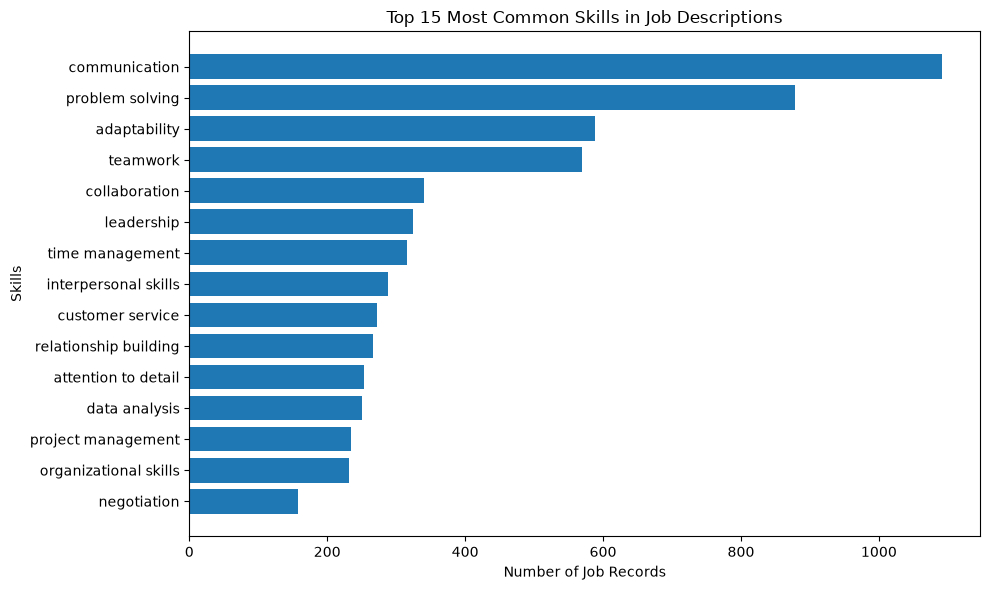

In [11]:
import matplotlib.pyplot as plt

top_skills = skill_counts.most_common(15)

skills = [skill for skill, count in top_skills]
counts = [count for skill, count in top_skills]

plt.figure(figsize=(10, 6))
plt.barh(skills[::-1], counts[::-1])
plt.xlabel("Number of Job Records")
plt.ylabel("Skills")
plt.title("Top 15 Most Common Skills in Job Descriptions")
plt.tight_layout()
plt.show()

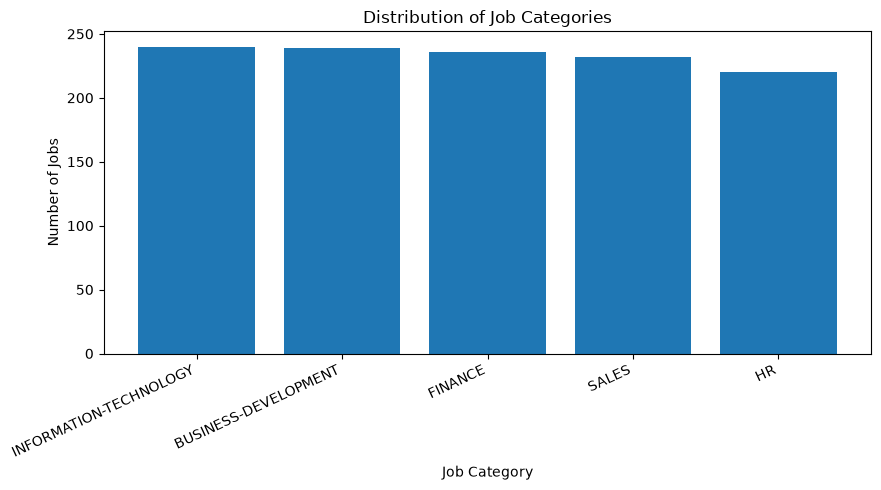

category
INFORMATION-TECHNOLOGY    240
BUSINESS-DEVELOPMENT      239
FINANCE                   236
SALES                     232
HR                        220
Name: count, dtype: int64


In [12]:
import matplotlib.pyplot as plt

category_counts = df["category"].value_counts()

plt.figure(figsize=(9, 5))
plt.bar(category_counts.index, category_counts.values)
plt.xlabel("Job Category")
plt.ylabel("Number of Jobs")
plt.title("Distribution of Job Categories")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

print(category_counts)

In [13]:
import pandas as pd

# Create a separate working copy
df_clean = df.copy()

# Clean job descriptions
df_clean["job_description_clean"] = (
    df_clean["job_description"]
    .astype(str)
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

# Clean job titles
df_clean["job_title_clean"] = (
    df_clean["job_title"]
    .astype(str)
    .str.lower()
    .str.strip()
)

# Normalize skill names without changing the original skill column
df_clean["skills_clean"] = df_clean["job_skill_set"].apply(
    lambda skills: list(dict.fromkeys(
        skill.lower().strip() for skill in skills
        if isinstance(skill, str) and skill.strip()
    ))
)

print("Text preparation complete!")
print("Total records:", len(df_clean))
print("Missing cleaned descriptions:",
      df_clean["job_description_clean"].isna().sum())

print("\nExample cleaned job title:")
print(df_clean["job_title_clean"].iloc[0])

print("\nExample cleaned skills:")
print(df_clean["skills_clean"].iloc[0][:10])

Text preparation complete!
Total records: 1167
Missing cleaned descriptions: 0

Example cleaned job title:
sr human resource generalist

Example cleaned skills:
['employee relations', 'talent acquisition', 'performance management', 'compensation and benefits', 'employment laws and regulations', 'analytical skills', 'employee benefits administration', 'hr policies and procedures', 'recruitment strategies', 'fmla']


In [14]:
from sklearn.model_selection import train_test_split

# Input text and target labels
X = df_clean["job_description_clean"]
y = df_clean["category"].str.strip()

# Split data: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining category distribution:")
print(y_train.value_counts())

print("\nTesting category distribution:")
print(y_test.value_counts())

Training records: 933
Testing records: 234

Training category distribution:
category
INFORMATION-TECHNOLOGY    192
BUSINESS-DEVELOPMENT      191
FINANCE                   189
SALES                     185
HR                        176
Name: count, dtype: int64

Testing category distribution:
category
INFORMATION-TECHNOLOGY    48
BUSINESS-DEVELOPMENT      48
FINANCE                   47
SALES                     47
HR                        44
Name: count, dtype: int64


In [15]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

# Build the NLP classification pipeline
model = Pipeline([
    ("tfidf", TfidfVectorizer(
        stop_words="english",
        ngram_range=(1, 2),
        max_features=10000
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Train the model
print("Training model...")

model.fit(X_train, y_train)

print("Model training completed successfully!")

Training model...


c:\Users\user\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


Model training completed successfully!


In [16]:
from sklearn.metrics import accuracy_score, classification_report

# Predict categories for unseen job descriptions
y_pred = model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print(f"Model Accuracy: {accuracy:.2%}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Model Accuracy: 93.16%

Classification Report:
                        precision    recall  f1-score   support

  BUSINESS-DEVELOPMENT       0.93      0.83      0.88        48
               FINANCE       0.98      0.96      0.97        47
                    HR       1.00      0.95      0.98        44
INFORMATION-TECHNOLOGY       0.94      0.96      0.95        48
                 SALES       0.83      0.96      0.89        47

              accuracy                           0.93       234
             macro avg       0.94      0.93      0.93       234
          weighted avg       0.94      0.93      0.93       234



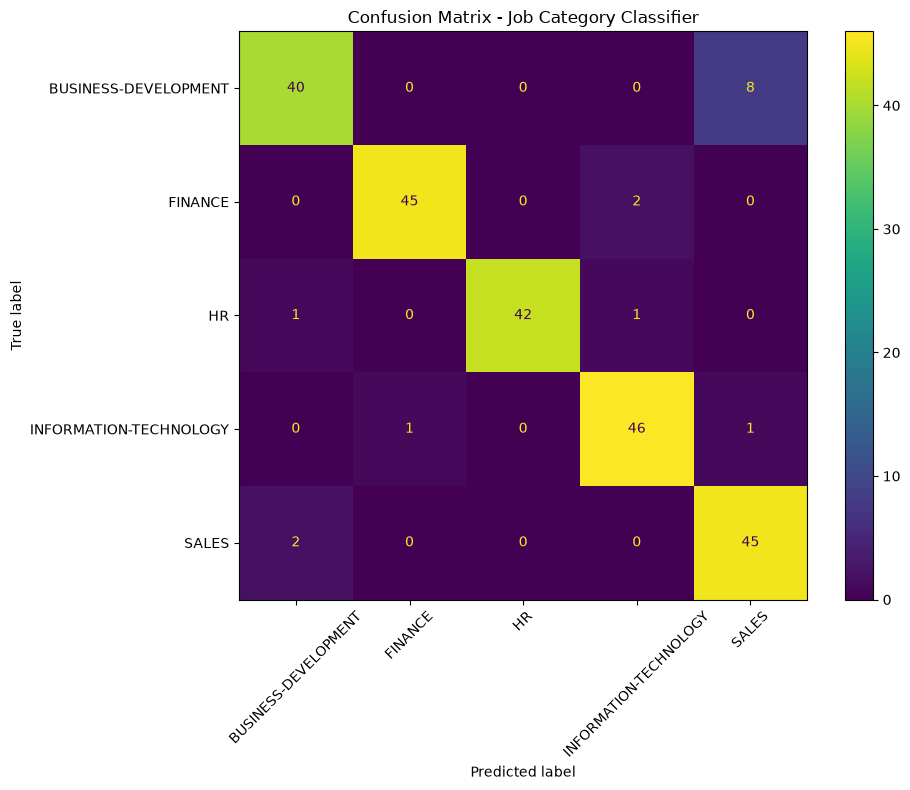

In [17]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

labels = sorted(y.unique())

cm = confusion_matrix(y_test, y_pred, labels=labels)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

fig, ax = plt.subplots(figsize=(10, 8))
display.plot(ax=ax, xticks_rotation=45, values_format="d")
plt.title("Confusion Matrix - Job Category Classifier")
plt.tight_layout()
plt.show()


In [18]:
import re

# Create a vocabulary of skills from the dataset
skill_vocabulary = sorted(
    set(
        skill.strip().lower()
        for skills in df_clean["skills_clean"]
        for skill in skills
        if skill.strip()
    ),
    key=len,
    reverse=True
)

print("Unique skills in vocabulary:", len(skill_vocabulary))

def extract_skills(text):
    text = str(text).lower()
    found_skills = []

    for skill in skill_vocabulary:
        pattern = r"(?<!\w)" + re.escape(skill) + r"(?!\w)"

        if re.search(pattern, text):
            found_skills.append(skill)

    return found_skills

# Test on the first job description
sample_text = df_clean["job_description_clean"].iloc[0]
predicted_skills = extract_skills(sample_text)

print("\nJob title:", df_clean["job_title"].iloc[0])
print("Extracted skills:", predicted_skills)
print("Number of skills extracted:", len(predicted_skills))

Unique skills in vocabulary: 4984

Job title: Sr Human Resource Generalist
Extracted skills: ['employee benefits administration', 'human capital management system', 'employment laws and regulations', 'compliance with employment laws', 'employee development programs', 'knowledge of employment laws', 'hr policies and procedures', 'compensation and benefits', 'hr audits and assessments', 'human capital management', 'professional development', 'learning and development', 'business administration', 'benefits administration', 'payroll administration', 'recruitment strategies', 'performance management', 'intellectual curiosity', 'salary administration', 'regulatory compliance', 'employee development', 'interpersonal skills', 'employee engagement', 'talent acquisition', 'detail orientation', 'employee relations', 'capital management', 'payroll processing', 'employee benefits', "bachelor's degree", 'analytical skills', 'job descriptions', 'hr certification', 'employment laws', 'human resources'

In [19]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Reference skills for the first job
actual_skills = set(df_clean["skills_clean"].iloc[0])

# Skills found by our extractor
predicted_skills_set = set(predicted_skills)

# Compare the two sets
correct_skills = actual_skills & predicted_skills_set
incorrect_skills = predicted_skills_set - actual_skills
missed_skills = actual_skills - predicted_skills_set

precision = len(correct_skills) / len(predicted_skills_set) if predicted_skills_set else 0
recall = len(correct_skills) / len(actual_skills) if actual_skills else 0
f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0

print("Reference skills:", len(actual_skills))
print("Extracted skills:", len(predicted_skills_set))
print("Correct matches:", len(correct_skills))

print(f"\nPrecision: {precision:.2%}")
print(f"Recall: {recall:.2%}")
print(f"F1-score: {f1:.2%}")

print("\nCorrect matches:")
print(sorted(correct_skills))

print("\nIncorrect matches:")
print(sorted(incorrect_skills))

print("\nMissed reference skills:")
print(sorted(missed_skills))

Reference skills: 27
Extracted skills: 77
Correct matches: 24

Precision: 31.17%
Recall: 88.89%
F1-score: 46.15%

Correct matches:
['ada', 'analytical skills', 'communication', 'compensation and benefits', 'eeoc guidelines', 'employee benefits administration', 'employee relations', 'employment laws and regulations', 'erisa', 'flsa', 'fmla', 'hr audits and assessments', 'hr policies and procedures', 'human capital management system', 'influence', 'intellectual curiosity', 'interpersonal skills', 'job design', 'payroll processing', 'performance management', 'professional development', 'recruitment strategies', 'salary administration', 'talent acquisition']

Incorrect matches:
['administration', 'audits', "bachelor's degree", 'benefits administration', 'business administration', 'capital management', 'compensation', 'compliance', 'compliance with employment laws', 'curiosity', 'decision making', 'design', 'detail orientation', 'development', 'discretion', 'drive', 'eeoc', 'employee benefi

In [20]:
import re

def extract_skills(text):
    text = str(text).lower()
    matches = []

    # Find every occurrence of each known skill
    for skill in skill_vocabulary:
        pattern = r"(?<!\w)" + re.escape(skill) + r"(?!\w)"

        for match in re.finditer(pattern, text):
            matches.append({
                "skill": skill,
                "start": match.start(),
                "end": match.end()
            })

    # Prefer longer phrases over shorter overlapping phrases
    matches.sort(
        key=lambda item: (
            -(item["end"] - item["start"]),
            item["start"]
        )
    )

    selected = []
    occupied_positions = set()

    for match in matches:
        positions = set(range(match["start"], match["end"]))

        if not positions.intersection(occupied_positions):
            selected.append(match)
            occupied_positions.update(positions)

    # Return unique skills in the order they appear in the text
    result = sorted(selected, key=lambda item: item["start"])

    return list(dict.fromkeys(item["skill"] for item in result))


# Test the improved extractor on the first job
sample_text = df_clean["job_description_clean"].iloc[0]
predicted_skills = extract_skills(sample_text)

print("Improved extracted skills:", len(predicted_skills))
print(predicted_skills)

Improved extracted skills: 60
['hr generalist', 'employee relations', 'talent acquisition', 'performance management', 'payroll', 'compensation and benefits', 'hr operations', 'payroll processing', 'employee engagement', 'labor law', 'regulatory compliance', 'hr strategies', 'implementation', 'drive', 'investigations', 'decision making', 'recruitment strategies', 'recruitment', 'sourcing', 'screening', 'job descriptions', 'learning and development', 'development', 'employee development programs', 'training', 'administration', 'compliance', 'hr policies and procedures', 'professional development', 'compliance with employment laws', 'hr audits and assessments', 'hr practices', 'employment laws and regulations', 'fmla', 'ada', 'flsa', 'erisa', 'eeoc guidelines', 'analytical skills', 'influence', 'organization', 'detail orientation', 'job design', 'writing', 'salary administration', 'employee benefits administration', 'communication', 'interpersonal skills', 'teams', 'human capital manageme

In [21]:
actual_skills = set(df_clean["skills_clean"].iloc[0])
predicted_skills_set = set(predicted_skills)

correct_skills = actual_skills & predicted_skills_set
incorrect_skills = predicted_skills_set - actual_skills
missed_skills = actual_skills - predicted_skills_set

precision = (
    len(correct_skills) / len(predicted_skills_set)
    if predicted_skills_set else 0
)

recall = (
    len(correct_skills) / len(actual_skills)
    if actual_skills else 0
)

f1 = (
    2 * precision * recall / (precision + recall)
    if precision + recall else 0
)

print("Reference skills:", len(actual_skills))
print("Extracted skills:", len(predicted_skills_set))
print("Correct matches:", len(correct_skills))

print(f"\nPrecision: {precision:.2%}")
print(f"Recall: {recall:.2%}")
print(f"F1-score: {f1:.2%}")

print("\nIncorrect matches:")
print(sorted(incorrect_skills))

print("\nMissed reference skills:")
print(sorted(missed_skills))

Reference skills: 27
Extracted skills: 60
Correct matches: 24

Precision: 40.00%
Recall: 88.89%
F1-score: 55.17%

Incorrect matches:
['administration', "bachelor's degree", 'business administration', 'compliance', 'compliance with employment laws', 'decision making', 'detail orientation', 'development', 'discretion', 'drive', 'employee development programs', 'employee engagement', 'focus', 'hr certification', 'hr generalist', 'hr operations', 'hr practices', 'hr strategies', 'human resources', 'implementation', 'investigations', 'job descriptions', 'labor law', 'learning and development', 'organization', 'payroll', 'payroll administration', 'professionalism', 'recruitment', 'regulatory compliance', 'screening', 'shrm-cp', 'sourcing', 'teams', 'training', 'writing']

Missed reference skills:
['change management', 'collaboration', 'confidentiality']


In [22]:
from sklearn.metrics import precision_score, recall_score, f1_score

results = []

for i in range(len(df_clean)):
    actual = set(df_clean["skills_clean"].iloc[i])
    predicted = set(extract_skills(df_clean["job_description_clean"].iloc[i]))

    correct = actual & predicted

    precision = len(correct) / len(predicted) if predicted else 0
    recall = len(correct) / len(actual) if actual else 0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    results.append({
        "job_id": df_clean["job_id"].iloc[i],
        "actual_count": len(actual),
        "predicted_count": len(predicted),
        "correct_count": len(correct),
        "precision": precision,
        "recall": recall,
        "f1_score": f1
    })

results_df = pd.DataFrame(results)

print("Jobs evaluated:", len(results_df))
print(f"Average precision: {results_df['precision'].mean():.2%}")
print(f"Average recall: {results_df['recall'].mean():.2%}")
print(f"Average F1-score: {results_df['f1_score'].mean():.2%}")

Jobs evaluated: 1167
Average precision: 30.15%
Average recall: 44.89%
Average F1-score: 34.62%


In [23]:
baseline_results = {
    "Method": "Rule-Based Skill Extraction",
    "Jobs Evaluated": 1167,
    "Average Precision": 0.3015,
    "Average Recall": 0.4489,
    "Average F1-Score": 0.3462
}

print("Baseline evaluation saved:")
for key, value in baseline_results.items():
    print(f"{key}: {value}")

Baseline evaluation saved:
Method: Rule-Based Skill Extraction
Jobs Evaluated: 1167
Average Precision: 0.3015
Average Recall: 0.4489
Average F1-Score: 0.3462


In [24]:
print("Total skills:", len(skill_vocabulary))
print("\nFirst 30 skills in vocabulary:")
print(skill_vocabulary[:30])

Total skills: 4984

First 30 skills in vocabulary:
['d365 f&sc modules (gl, ap, ar, cash management, fixed assets, project management & accounting)', 'crm tools (hubspot, outreach.io, linkedin sales navigator, zoominfo)', 'enterprise governance, risk and compliance systems (e.g., archer)', 'ms office (word, powerpoint, excel, outlook, teams, sharepoint)', 'financial software (e.g., sunsystems, infor q&a, birchstreet)', 'lightweight directory access protocol (ldap) authentication', 'microsoft office (excel, powerpoint, word, access, visio)', 'professional certifications (axis, milestone, avigilon)', 'microsoft office (excel, word, powerpoint, sharepoint)', 'microsoft certified desktop support technician (mcdst)', 'pc imaging software (mdt, sccm, smartdeploy, acronis)', 'ms office (word, excel, powerpoint, outlook, onenote)', 'professional accounting qualification (acca/cpa/cima)', 'security frameworks (iso, nist, cobit, hipaa/hitech)', 'information technology infrastructure library (iti

In [25]:
skill_vocabulary_clean = sorted(
    {
        re.sub(r"\s+", " ", skill.lower().strip())
        for skill in skill_vocabulary
        if isinstance(skill, str) and skill.strip()
    },
    key=len,
    reverse=True
)

print("Original vocabulary:", len(skill_vocabulary))
print("Clean vocabulary:", len(skill_vocabulary_clean))
print("\nFirst 20 cleaned skills:")
print(skill_vocabulary_clean[:20])

Original vocabulary: 4984
Clean vocabulary: 4984

First 20 cleaned skills:
['d365 f&sc modules (gl, ap, ar, cash management, fixed assets, project management & accounting)', 'crm tools (hubspot, outreach.io, linkedin sales navigator, zoominfo)', 'enterprise governance, risk and compliance systems (e.g., archer)', 'ms office (word, powerpoint, excel, outlook, teams, sharepoint)', 'financial software (e.g., sunsystems, infor q&a, birchstreet)', 'lightweight directory access protocol (ldap) authentication', 'microsoft office (excel, powerpoint, word, access, visio)', 'professional certifications (axis, milestone, avigilon)', 'microsoft office (excel, word, powerpoint, sharepoint)', 'microsoft certified desktop support technician (mcdst)', 'pc imaging software (mdt, sccm, smartdeploy, acronis)', 'ms office (word, excel, powerpoint, outlook, onenote)', 'professional accounting qualification (acca/cpa/cima)', 'security frameworks (iso, nist, cobit, hipaa/hitech)', 'information technology inf

In [26]:
import re
import time

skill_pattern = re.compile(
    r"(?<!\w)(" +
    "|".join(re.escape(skill) for skill in skill_vocabulary_clean) +
    r")(?!\w)"
)

def extract_skills_fast(text):
    text = str(text).lower()
    return list(dict.fromkeys(skill_pattern.findall(text)))

# Test on the first job description
sample_text = df_clean["job_description_clean"].iloc[0]

start_time = time.time()
fast_skills = extract_skills_fast(sample_text)
elapsed_time = time.time() - start_time

print("Extracted skills:", len(fast_skills))
print("Time taken:", round(elapsed_time, 4), "seconds")
print(fast_skills)

Extracted skills: 60
Time taken: 0.0206 seconds
['hr generalist', 'employee relations', 'talent acquisition', 'performance management', 'payroll', 'compensation and benefits', 'hr operations', 'payroll processing', 'employee engagement', 'labor law', 'regulatory compliance', 'hr strategies', 'implementation', 'drive', 'investigations', 'decision making', 'recruitment strategies', 'recruitment', 'sourcing', 'screening', 'job descriptions', 'learning and development', 'development', 'employee development programs', 'training', 'administration', 'compliance', 'hr policies and procedures', 'professional development', 'compliance with employment laws', 'hr audits and assessments', 'hr practices', 'knowledge of employment laws', 'fmla', 'ada', 'flsa', 'erisa', 'eeoc guidelines', 'analytical skills', 'influence', 'organization', 'detail orientation', 'job design', 'writing', 'salary administration', 'employee benefits administration', 'communication', 'interpersonal skills', 'teams', 'human c

In [27]:
old_skills = set(extract_skills(sample_text))
fast_skills_set = set(fast_skills)

print("Old extractor:", len(old_skills), "skills")
print("Fast extractor:", len(fast_skills_set), "skills")
print("Skills found by both:", len(old_skills & fast_skills_set))

print("\nOnly in old extractor:")
print(sorted(old_skills - fast_skills_set))

print("\nOnly in fast extractor:")
print(sorted(fast_skills_set - old_skills))

Old extractor: 60 skills
Fast extractor: 60 skills
Skills found by both: 59

Only in old extractor:
['employment laws and regulations']

Only in fast extractor:
['knowledge of employment laws']


In [28]:
actual = set(df_clean["skills_clean"].iloc[0])
predicted = set(fast_skills)

correct = actual & predicted

precision = len(correct) / len(predicted) if predicted else 0
recall = len(correct) / len(actual) if actual else 0
f1 = (
    2 * precision * recall / (precision + recall)
    if precision + recall else 0
)

print("Correct matches:", len(correct))
print(f"Precision: {precision:.2%}")
print(f"Recall: {recall:.2%}")
print(f"F1-score: {f1:.2%}")

Correct matches: 23
Precision: 38.33%
Recall: 85.19%
F1-score: 52.87%


In [29]:
generic_terms = {
    "drive", "focus", "development", "implementation",
    "administration", "organization", "writing",
    "influence", "teams", "compliance"
}

print("Generic terms found in vocabulary:")
print([skill for skill in skill_vocabulary_clean if skill in generic_terms])

print("\nTotal generic terms to review:", len(generic_terms))


Generic terms found in vocabulary:
['implementation', 'administration', 'organization', 'development', 'compliance', 'influence', 'writing', 'drive', 'teams', 'focus']

Total generic terms to review: 10


In [30]:
generic_terms = {
    "drive", "focus", "development", "implementation",
    "administration", "organization", "writing",
    "influence", "teams", "compliance"
}

skill_vocabulary_filtered = [
    skill for skill in skill_vocabulary_clean
    if skill not in generic_terms
]

print("Original vocabulary:", len(skill_vocabulary_clean))
print("Filtered vocabulary:", len(skill_vocabulary_filtered))
print("Terms excluded:", len(skill_vocabulary_clean) - len(skill_vocabulary_filtered))

Original vocabulary: 4984
Filtered vocabulary: 4974
Terms excluded: 10


In [31]:
filtered_pattern = re.compile(
    r"(?<!\w)(" +
    "|".join(
        re.escape(skill) for skill in skill_vocabulary_filtered
    ) +
    r")(?!\w)"
)

def extract_skills_filtered(text):
    text = str(text).lower()
    return list(dict.fromkeys(filtered_pattern.findall(text)))

filtered_skills = extract_skills_filtered(sample_text)

actual = set(df_clean["skills_clean"].iloc[0])
predicted = set(filtered_skills)
correct = actual & predicted

precision = len(correct) / len(predicted) if predicted else 0
recall = len(correct) / len(actual) if actual else 0
f1 = (
    2 * precision * recall / (precision + recall)
    if precision + recall else 0
)

print("Extracted skills:", len(predicted))
print("Correct matches:", len(correct))
print(f"Precision: {precision:.2%}")
print(f"Recall: {recall:.2%}")
print(f"F1-score: {f1:.2%}")

Extracted skills: 50
Correct matches: 22
Precision: 44.00%
Recall: 81.48%
F1-score: 57.14%


In [32]:
comparison = pd.DataFrame([
    {
        "Method": "Improved old extractor",
        "Precision": 40.00,
        "Recall": 88.89,
        "F1-score": 55.17
    },
    {
        "Method": "Fast extractor",
        "Precision": 38.33,
        "Recall": 85.19,
        "F1-score": 52.87
    },
    {
        "Method": "Filtered fast extractor",
        "Precision": 44.00,
        "Recall": 81.48,
        "F1-score": 57.14
    }
])

comparison

,Method,Precision,Recall,F1-score
0,Improved old extractor,40.00,88.89,55.17
1,Fast extractor,38.33,85.19,52.87
2,Filtered fast extractor,44.00,81.48,57.14


In [33]:
results_50 = []

for i in range(min(50, len(df_clean))):
    actual = set(df_clean["skills_clean"].iloc[i])
    predicted = set(
        extract_skills_filtered(df_clean["job_description_clean"].iloc[i])
    )

    correct = actual & predicted

    p = len(correct) / len(predicted) if predicted else 0
    r = len(correct) / len(actual) if actual else 0
    f1 = 2 * p * r / (p + r) if p + r else 0

    results_50.append({
        "precision": p,
        "recall": r,
        "f1_score": f1
    })

results_50_df = pd.DataFrame(results_50)

print("Jobs evaluated:", len(results_50_df))
print(f"Average precision: {results_50_df['precision'].mean():.2%}")
print(f"Average recall: {results_50_df['recall'].mean():.2%}")
print(f"Average F1-score: {results_50_df['f1_score'].mean():.2%}")

Jobs evaluated: 50
Average precision: 28.58%
Average recall: 45.98%
Average F1-score: 34.36%


In [34]:
from collections import Counter

skill_counts = Counter()

for text in df_clean["job_description_clean"].iloc[:50]:
    extracted = extract_skills_filtered(text)
    skill_counts.update(set(extracted))

top_skills = skill_counts.most_common(15)

skills_df = pd.DataFrame(
    top_skills,
    columns=["Skill", "Frequency"]
)

print(skills_df)

                     Skill  Frequency
0          human resources         42
1               employment         30
2                 training         26
3               management         26
4       employee relations         24
5               leadership         24
6             compensation         23
7              recruitment         22
8                  payroll         19
9               onboarding         18
10      talent acquisition         16
11  performance management         16
12     attention to detail         15
13       bachelor's degree         14
14                   excel         14


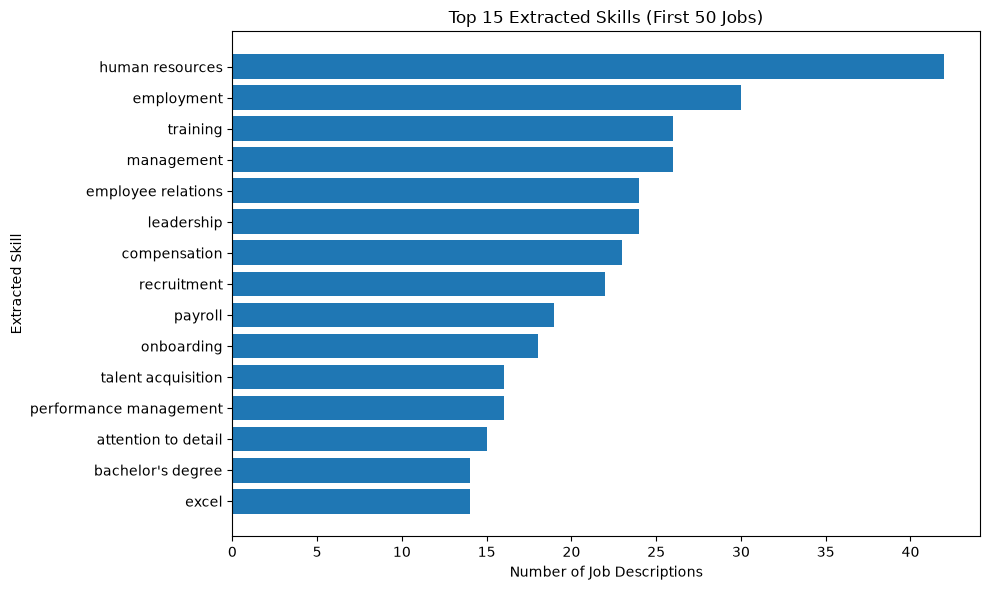

In [35]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.barh(
    skills_df["Skill"][::-1],
    skills_df["Frequency"][::-1]
)

plt.xlabel("Number of Job Descriptions")
plt.ylabel("Extracted Skill")
plt.title("Top 15 Extracted Skills (First 50 Jobs)")
plt.tight_layout()
plt.show()

In [36]:
actual_counts = []
predicted_counts = []

for i in range(min(50, len(df_clean))):
    actual = set(df_clean["skills_clean"].iloc[i])
    predicted = set(
        extract_skills_filtered(df_clean["job_description_clean"].iloc[i])
    )

    actual_counts.append(len(actual))
    predicted_counts.append(len(predicted))

print("Average reference skills per job:", round(sum(actual_counts) / len(actual_counts), 2))
print("Average extracted skills per job:", round(sum(predicted_counts) / len(predicted_counts), 2))

Average reference skills per job: 19.28
Average extracted skills per job: 32.94


In [37]:
i = 0

actual = set(df_clean["skills_clean"].iloc[i])
predicted = set(
    extract_skills_filtered(df_clean["job_description_clean"].iloc[i])
)

print("Job title:", df_clean["job_title"].iloc[i])
print("\nCorrect matches:")
print(sorted(actual & predicted))

print("\nExtracted but not in reference:")
print(sorted(predicted - actual))

print("\nReference skills missed:")
print(sorted(actual - predicted))

Job title: Sr Human Resource Generalist

Correct matches:
['ada', 'analytical skills', 'communication', 'compensation and benefits', 'eeoc guidelines', 'employee benefits administration', 'employee relations', 'erisa', 'flsa', 'fmla', 'hr audits and assessments', 'hr policies and procedures', 'human capital management system', 'intellectual curiosity', 'interpersonal skills', 'job design', 'payroll processing', 'performance management', 'professional development', 'recruitment strategies', 'salary administration', 'talent acquisition']

Extracted but not in reference:
["bachelor's degree", 'business administration', 'compliance with employment laws', 'decision making', 'detail orientation', 'discretion', 'employee development programs', 'employee engagement', 'hr certification', 'hr generalist', 'hr operations', 'hr practices', 'hr strategies', 'human resources', 'investigations', 'job descriptions', 'knowledge of employment laws', 'labor law', 'learning and development', 'payroll', 'p

In [38]:
non_skill_terms = {
    "bachelor's degree",
    "business administration",
    "hr generalist",
    "human resources",
    "hr certification",
    "shrm-cp",
    "job descriptions"
}

skill_vocabulary_v2 = [
    skill for skill in skill_vocabulary_filtered
    if skill not in non_skill_terms
]

print("Previous vocabulary:", len(skill_vocabulary_filtered))
print("New vocabulary:", len(skill_vocabulary_v2))
print("Terms excluded:", len(skill_vocabulary_filtered) - len(skill_vocabulary_v2))

Previous vocabulary: 4974
New vocabulary: 4967
Terms excluded: 7


In [39]:
pattern_v2 = re.compile(
    r"(?<!\w)(" +
    "|".join(
        re.escape(skill) for skill in skill_vocabulary_v2
    ) +
    r")(?!\w)"
)

def extract_skills_v2(text):
    text = str(text).lower()
    return list(dict.fromkeys(pattern_v2.findall(text)))

# Test on the same HR job
predicted_v2 = set(
    extract_skills_v2(df_clean["job_description_clean"].iloc[0])
)
actual = set(df_clean["skills_clean"].iloc[0])
correct_v2 = actual & predicted_v2

precision_v2 = len(correct_v2) / len(predicted_v2) if predicted_v2 else 0
recall_v2 = len(correct_v2) / len(actual) if actual else 0
f1_v2 = (
    2 * precision_v2 * recall_v2 / (precision_v2 + recall_v2)
    if precision_v2 + recall_v2 else 0
)

print("Extracted skills:", len(predicted_v2))
print("Correct matches:", len(correct_v2))
print(f"Precision: {precision_v2:.2%}")
print(f"Recall: {recall_v2:.2%}")
print(f"F1-score: {f1_v2:.2%}")

Extracted skills: 43
Correct matches: 22
Precision: 51.16%
Recall: 81.48%
F1-score: 62.86%


In [40]:
results_v2 = []

for i in range(min(50, len(df_clean))):
    actual = set(df_clean["skills_clean"].iloc[i])
    predicted = set(
        extract_skills_v2(df_clean["job_description_clean"].iloc[i])
    )

    correct = actual & predicted

    p = len(correct) / len(predicted) if predicted else 0
    r = len(correct) / len(actual) if actual else 0
    f1 = 2 * p * r / (p + r) if p + r else 0

    results_v2.append({
        "precision": p,
        "recall": r,
        "f1_score": f1
    })

results_v2_df = pd.DataFrame(results_v2)

print("Jobs evaluated:", len(results_v2_df))
print(f"Average precision: {results_v2_df['precision'].mean():.2%}")
print(f"Average recall: {results_v2_df['recall'].mean():.2%}")
print(f"Average F1-score: {results_v2_df['f1_score'].mean():.2%}")

Jobs evaluated: 50
Average precision: 30.18%
Average recall: 45.42%
Average F1-score: 35.18%


In [41]:
comparison_50 = []

for method_name, extractor in [
    ("Filtered extractor", extract_skills_filtered),
    ("V2 extractor", extract_skills_v2)
]:
    scores = []

    for i in range(min(50, len(df_clean))):
        actual = set(df_clean["skills_clean"].iloc[i])
        predicted = set(
            extractor(df_clean["job_description_clean"].iloc[i])
        )

        correct = actual & predicted
        p = len(correct) / len(predicted) if predicted else 0
        r = len(correct) / len(actual) if actual else 0
        f1 = 2 * p * r / (p + r) if p + r else 0

        scores.append([p, r, f1])

    scores_df = pd.DataFrame(
        scores, columns=["precision", "recall", "f1_score"]
    )

    comparison_50.append({
        "Method": method_name,
        "Precision": round(scores_df["precision"].mean() * 100, 2),
        "Recall": round(scores_df["recall"].mean() * 100, 2),
        "F1-score": round(scores_df["f1_score"].mean() * 100, 2)
    })

pd.DataFrame(comparison_50)

,Method,Precision,Recall,F1-score
0,Filtered extractor,28.58,45.98,34.36
1,V2 extractor,30.18,45.42,35.18


In [42]:
final_comparison = pd.DataFrame([
    {
        "Method": "Filtered extractor",
        "Precision (%)": 28.58,
        "Recall (%)": 45.98,
        "F1-score (%)": 34.36
    },
    {
        "Method": "V2 extractor",
        "Precision (%)": 30.18,
        "Recall (%)": 45.42,
        "F1-score (%)": 35.18
    }
])

final_comparison

,Method,Precision (%),Recall (%),F1-score (%)
0,Filtered extractor,28.58,45.98,34.36
1,V2 extractor,30.18,45.42,35.18


In [43]:
import importlib.util

print("spaCy installed:", importlib.util.find_spec("spacy") is not None)
print("NLTK installed:", importlib.util.find_spec("nltk") is not None)

spaCy installed: False
NLTK installed: False


In [44]:
%pip install spacy

   ---------------------------------------- 0.0/15.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/15.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/15.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/15.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/15.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/15.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/15.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/15.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/15.2 MB ? eta -:--:--
    --------------------------------------- 0.3/15.2 MB ? eta -:--:--
    --------------------------------------- 0.3/15.2 MB ? eta -:--:--
    --------------------------------------- 0.3/15.2 MB ? eta -:--:--
    --------------------------------------- 0.3/15.2 MB ? eta -:--:--
    --------------------------------------- 0.3/15.2 MB ? eta -:--:--
    ----------------


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [45]:
import spacy

print("spaCy version:", spacy.__version__)

spaCy version: 3.8.18


In [46]:
%pip install https://github.com/explosion/spacy-models/releases/download/en_core_web_sm-3.8.0/en_core_web_sm-3.8.0-py3-none-any.whl

     ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
     ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
     ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
     ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
     ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
     ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
     ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
     ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
     ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
     ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
     ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
      --------------------------------------- 0.3/12.8 MB ? eta -:--:--
      --------------------------------------- 0.3/12.8 MB ? eta -:--:--
      --------------------------------------- 0.3/12.8 MB ? eta 


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [47]:
import spacy

nlp = spacy.load("en_core_web_sm")

sample_text = df_clean["job_description_clean"].iloc[0]
doc = nlp(sample_text)

for token in list(doc)[:30]:
    print(token.text, "|", token.pos_, "|", token.lemma_)

summary | VERB | summary
the | DET | the
sr | PROPN | sr
. | PUNCT | .
hr | PROPN | hr
generalist | NOUN | generalist
provides | VERB | provide
hr | PROPN | hr
expertise | NOUN | expertise
across | ADP | across
various | ADJ | various
functions | NOUN | function
including | VERB | include
employee | NOUN | employee
relations | NOUN | relation
, | PUNCT | ,
talent | NOUN | talent
acquisition | NOUN | acquisition
, | PUNCT | ,
performance | NOUN | performance
management | NOUN | management
, | PUNCT | ,
payroll | NOUN | payroll
, | PUNCT | ,
compensation | NOUN | compensation
and | CCONJ | and
benefits | NOUN | benefit
. | PUNCT | .
the | DET | the
sr | PROPN | sr


In [48]:
from spacy.matcher import PhraseMatcher

matcher = PhraseMatcher(nlp.vocab, attr="LOWER")

patterns = [nlp.make_doc(skill) for skill in skill_vocabulary_v2]
matcher.add("SKILL", patterns)

print("Skills loaded into matcher:", len(patterns))

Skills loaded into matcher: 4967


In [49]:
def extract_skills_spacy(text):
    doc = nlp(str(text).lower())
    matches = matcher(doc)

    found_skills = {
        doc[start:end].text
        for _, start, end in matches
    }

    return sorted(found_skills)

sample_text = df_clean["job_description_clean"].iloc[0]

spacy_skills = extract_skills_spacy(sample_text)

print("Total skills extracted:", len(spacy_skills))
print("\nExtracted skills:")
print(spacy_skills)

Total skills extracted: 58

Extracted skills:
['ada', 'analytical skills', 'audits', 'benefits administration', 'capital management', 'communication', 'compensation', 'compensation and benefits', 'compliance with employment laws', 'curiosity', 'decision making', 'design', 'detail orientation', 'discretion', 'eeoc', 'employee benefits', 'employee benefits administration', 'employee development', 'employee development programs', 'employee engagement', 'employee relations', 'employment', 'employment laws', 'employment laws and regulations', 'engagement', 'erisa', 'flsa', 'fmla', 'hr audits', 'hr audits and assessments', 'hr operations', 'hr policies', 'hr policies and procedures', 'hr practices', 'hr strategies', 'human capital management', 'human capital management system', 'intellectual curiosity', 'interpersonal skills', 'investigations', 'job design', 'knowledge of employment laws', 'labor law', 'learning and development', 'management', 'payroll', 'payroll administration', 'payroll pr

In [50]:
actual_skills = set(df_clean["skills_clean"].iloc[0])
predicted_skills = set(spacy_skills)

correct = actual_skills & predicted_skills
false_positives = predicted_skills - actual_skills
missed = actual_skills - predicted_skills

precision = len(correct) / len(predicted_skills) if predicted_skills else 0
recall = len(correct) / len(actual_skills) if actual_skills else 0
f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0

print("Reference skills:", len(actual_skills))
print("Extracted skills:", len(predicted_skills))
print("Correct matches:", len(correct))
print(f"Precision: {precision * 100:.2f}%")
print(f"Recall: {recall * 100:.2f}%")
print(f"F1-score: {f1 * 100:.2f}%")

print("\nMissed skills:", sorted(missed))

Reference skills: 27
Extracted skills: 58
Correct matches: 21
Precision: 36.21%
Recall: 77.78%
F1-score: 49.41%

Missed skills: ['change management', 'collaboration', 'confidentiality', 'eeoc guidelines', 'influence', 'salary administration']


In [51]:
from spacy.util import filter_spans

def extract_skills_spacy_clean(text):
    doc = nlp(str(text).lower())
    matches = matcher(doc)

    spans = [
        doc[start:end]
        for _, start, end in matches
    ]

    longest_spans = filter_spans(spans)

    return list(dict.fromkeys(span.text for span in longest_spans))

spacy_clean_skills = extract_skills_spacy_clean(sample_text)

print("Skills extracted:", len(spacy_clean_skills))
print(spacy_clean_skills)

Skills extracted: 42
['employee relations', 'talent acquisition', 'performance management', 'payroll', 'compensation and benefits', 'hr operations', 'payroll processing', 'employee engagement', 'labor law', 'regulatory compliance', 'hr strategies', 'investigations', 'decision making', 'recruitment strategies', 'recruitment', 'sourcing', 'screening', 'learning and development', 'employee development programs', 'training', 'hr policies and procedures', 'professional development', 'compliance with employment laws', 'hr audits and assessments', 'hr practices', 'knowledge of employment laws', 'fmla', 'ada', 'flsa', 'erisa', 'eeoc', 'analytical skills', 'detail orientation', 'job design', 'employee benefits administration', 'communication', 'interpersonal skills', 'human capital management system', 'discretion', 'professionalism', 'intellectual curiosity', 'payroll administration']


In [52]:
actual_skills = set(df_clean["skills_clean"].iloc[0])
predicted_skills = set(spacy_clean_skills)

correct = actual_skills & predicted_skills

precision = len(correct) / len(predicted_skills) if predicted_skills else 0
recall = len(correct) / len(actual_skills) if actual_skills else 0
f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0

print("Reference skills:", len(actual_skills))
print("Extracted skills:", len(predicted_skills))
print("Correct matches:", len(correct))
print(f"Precision: {precision * 100:.2f}%")
print(f"Recall: {recall * 100:.2f}%")
print(f"F1-score: {f1 * 100:.2f}%")

Reference skills: 27
Extracted skills: 42
Correct matches: 20
Precision: 47.62%
Recall: 74.07%
F1-score: 57.97%


In [53]:
actual = set(df_clean["skills_clean"].iloc[0])

methods = {
    "V2 extractor": extract_skills_v2(sample_text),
    "spaCy matcher": spacy_skills,
    "spaCy cleaned": spacy_clean_skills
}

comparison = []

for name, skills in methods.items():
    predicted = set(skills)
    correct = actual & predicted

    precision = len(correct) / len(predicted) if predicted else 0
    recall = len(correct) / len(actual) if actual else 0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    comparison.append({
        "Method": name,
        "Extracted": len(predicted),
        "Correct": len(correct),
        "Precision (%)": round(precision * 100, 2),
        "Recall (%)": round(recall * 100, 2),
        "F1-score (%)": round(f1 * 100, 2)
    })

pd.DataFrame(comparison)

,Method,Extracted,Correct,Precision (%),Recall (%),F1-score (%)
0,V2 extractor,43,22,51.16,81.48,62.86
1,spaCy matcher,58,21,36.21,77.78,49.41
2,spaCy cleaned,42,20,47.62,74.07,57.97


In [54]:
comparison_results = []

methods = [
    ("V2 extractor", extract_skills_v2),
    ("spaCy matcher", extract_skills_spacy),
    ("spaCy cleaned", extract_skills_spacy_clean)
]

for method_name, extractor in methods:
    scores = []

    for i in range(min(50, len(df_clean))):
        actual = set(df_clean["skills_clean"].iloc[i])
        predicted = set(extractor(df_clean["job_description_clean"].iloc[i]))

        correct = actual & predicted

        precision = len(correct) / len(predicted) if predicted else 0
        recall = len(correct) / len(actual) if actual else 0
        f1 = (
            2 * precision * recall / (precision + recall)
            if precision + recall else 0
        )

        scores.append([precision, recall, f1])

    scores_df = pd.DataFrame(
        scores, columns=["Precision", "Recall", "F1-score"]
    )

    comparison_results.append({
        "Method": method_name,
        "Precision (%)": round(scores_df["Precision"].mean() * 100, 2),
        "Recall (%)": round(scores_df["Recall"].mean() * 100, 2),
        "F1-score (%)": round(scores_df["F1-score"].mean() * 100, 2)
    })

pd.DataFrame(comparison_results)

,Method,Precision (%),Recall (%),F1-score (%)
0,V2 extractor,30.18,45.42,35.18
1,spaCy matcher,27.57,44.64,33.00
2,spaCy cleaned,29.29,41.80,33.38


In [55]:
sample_indices = range(min(50, len(df_clean)))

skill_counts = [
    len(extract_skills_v2(df_clean["job_description_clean"].iloc[i]))
    for i in sample_indices
]

print("Jobs analyzed:", len(skill_counts))
print("Average extracted skills:", round(sum(skill_counts) / len(skill_counts), 2))
print("Minimum extracted skills:", min(skill_counts))
print("Maximum extracted skills:", max(skill_counts))

Jobs analyzed: 50
Average extracted skills: 31.14
Minimum extracted skills: 6
Maximum extracted skills: 73


In [56]:
from collections import Counter

false_positive_counts = Counter()

for i in range(min(50, len(df_clean))):
    actual = set(df_clean["skills_clean"].iloc[i])
    predicted = set(extract_skills_v2(df_clean["job_description_clean"].iloc[i]))

    false_positives = predicted - actual
    false_positive_counts.update(false_positives)

top_false_positives = pd.DataFrame(
    false_positive_counts.most_common(20),
    columns=["Skill candidate", "False-positive count"]
)

top_false_positives

,Skill candidate,False-positive count
0,employment,29
1,management,26
2,training,23
3,compensation,21
4,payroll,19
5,recruitment,12
6,strategy,12
7,bachelor’s degree,12
8,planning,11
9,retention,11


In [57]:
candidate_terms = [
    "employment", "management", "training", "compensation",
    "payroll", "recruitment", "strategy", "bachelor’s degree",
    "planning", "retention", "excel", "word", "audits",
    "proactive", "competitive", "guidance", "leadership",
    "documentation", "technology", "travel"
]

candidate_review = []

for skill in candidate_terms:
    reference_count = sum(
        skill in set(skills)
        for skills in df_clean["skills_clean"].iloc[:50]
    )

    candidate_review.append({
        "Candidate": skill,
        "Reference-label count": reference_count,
        "Predicted false-positive count": false_positive_counts[skill]
    })

pd.DataFrame(candidate_review)

,Candidate,Reference-label count,Predicted false-positive count
0,employment,1,29
1,management,0,26
2,training,3,23
3,compensation,2,21
4,payroll,0,19
5,recruitment,10,12
6,strategy,0,12
7,bachelor’s degree,0,12
8,planning,0,11
9,retention,0,11


In [58]:
terms_to_exclude = {
    "employment",
    "bachelor’s degree",
    "word",
    "proactive",
    "competitive",
    "guidance",
    "travel"
}

skill_vocabulary_v3 = [
    skill for skill in skill_vocabulary_v2
    if skill not in terms_to_exclude
]

pattern_v3 = re.compile(
    r"(?<!\w)("
    + "|".join(re.escape(skill) for skill in skill_vocabulary_v3)
    + r")(?!\w)"
)

def extract_skills_v3(text):
    text = str(text).lower()
    return list(dict.fromkeys(pattern_v3.findall(text)))

print("V2 vocabulary:", len(skill_vocabulary_v2))
print("V3 vocabulary:", len(skill_vocabulary_v3))

V2 vocabulary: 4967
V3 vocabulary: 4960


In [59]:
results_v2_v3 = []

for name, extractor in [
    ("V2 extractor", extract_skills_v2),
    ("V3 extractor", extract_skills_v3)
]:
    scores = []

    for i in range(min(50, len(df_clean))):
        actual = set(df_clean["skills_clean"].iloc[i])
        predicted = set(extractor(df_clean["job_description_clean"].iloc[i]))
        correct = actual & predicted

        p = len(correct) / len(predicted) if predicted else 0
        r = len(correct) / len(actual) if actual else 0
        f1 = 2 * p * r / (p + r) if p + r else 0

        scores.append([p, r, f1])

    score_df = pd.DataFrame(scores, columns=["Precision", "Recall", "F1"])

    results_v2_v3.append({
        "Method": name,
        "Precision (%)": round(score_df["Precision"].mean() * 100, 2),
        "Recall (%)": round(score_df["Recall"].mean() * 100, 2),
        "F1-score (%)": round(score_df["F1"].mean() * 100, 2)
    })

pd.DataFrame(results_v2_v3)

,Method,Precision (%),Recall (%),F1-score (%)
0,V2 extractor,30.18,45.42,35.18
1,V3 extractor,31.89,45.24,36.28


In [60]:
import time

all_results_v3 = []
start_time = time.time()

for i in range(len(df_clean)):
    actual = set(df_clean["skills_clean"].iloc[i])
    predicted = set(extract_skills_v3(df_clean["job_description_clean"].iloc[i]))
    correct = actual & predicted

    precision = len(correct) / len(predicted) if predicted else 0
    recall = len(correct) / len(actual) if actual else 0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    all_results_v3.append([precision, recall, f1])

scores_v3 = pd.DataFrame(
    all_results_v3,
    columns=["Precision", "Recall", "F1-score"]
)

print("Jobs evaluated:", len(scores_v3))
print(f"Average precision: {scores_v3['Precision'].mean() * 100:.2f}%")
print(f"Average recall: {scores_v3['Recall'].mean() * 100:.2f}%")
print(f"Average F1-score: {scores_v3['F1-score'].mean() * 100:.2f}%")
print(f"Time taken: {(time.time() - start_time) / 60:.2f} minutes")

Jobs evaluated: 1167
Average precision: 34.26%
Average recall: 44.30%
Average F1-score: 37.12%
Time taken: 0.51 minutes


In [61]:
final_skill_results = pd.DataFrame([
    {
        "Method": "V3 rule-based extractor",
        "Jobs evaluated": len(scores_v3),
        "Precision (%)": round(scores_v3["Precision"].mean() * 100, 2),
        "Recall (%)": round(scores_v3["Recall"].mean() * 100, 2),
        "F1-score (%)": round(scores_v3["F1-score"].mean() * 100, 2)
    }
])

final_skill_results

,Method,Jobs evaluated,Precision (%),Recall (%),F1-score (%)
0,V3 rule-based extractor,1167,34.26,44.3,37.12


In [62]:
v2_results = []

for i in range(len(df_clean)):
    actual = set(df_clean["skills_clean"].iloc[i])
    predicted = set(extract_skills_v2(df_clean["job_description_clean"].iloc[i]))
    correct = actual & predicted

    p = len(correct) / len(predicted) if predicted else 0
    r = len(correct) / len(actual) if actual else 0
    f1 = 2 * p * r / (p + r) if p + r else 0

    v2_results.append([p, r, f1])

scores_v2 = pd.DataFrame(
    v2_results,
    columns=["Precision", "Recall", "F1-score"]
)

full_comparison = pd.DataFrame([
    {
        "Method": "V2 extractor",
        "Precision (%)": round(scores_v2["Precision"].mean() * 100, 2),
        "Recall (%)": round(scores_v2["Recall"].mean() * 100, 2),
        "F1-score (%)": round(scores_v2["F1-score"].mean() * 100, 2)
    },
    {
        "Method": "V3 extractor",
        "Precision (%)": round(scores_v3["Precision"].mean() * 100, 2),
        "Recall (%)": round(scores_v3["Recall"].mean() * 100, 2),
        "F1-score (%)": round(scores_v3["F1-score"].mean() * 100, 2)
    }
])

full_comparison


,Method,Precision (%),Recall (%),F1-score (%)
0,V2 extractor,32.71,44.42,36.18
1,V3 extractor,34.26,44.30,37.12


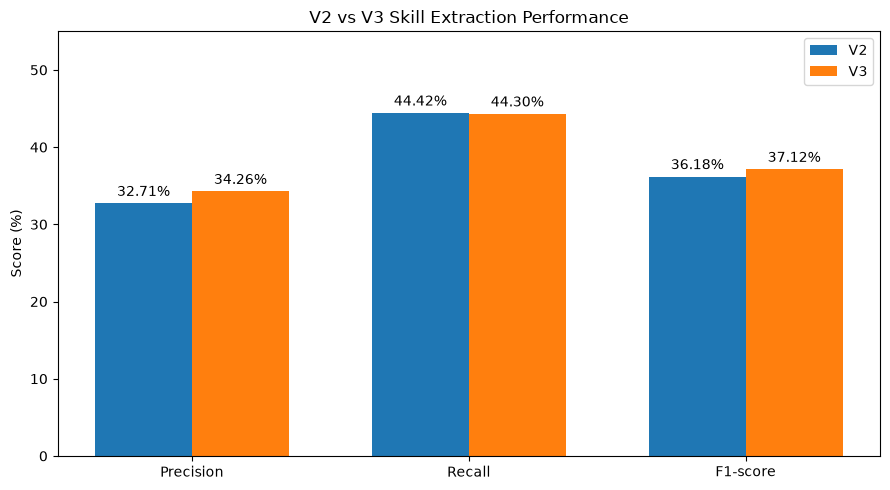

In [63]:
import matplotlib.pyplot as plt
import numpy as np

metrics = ["Precision", "Recall", "F1-score"]

v2_scores = [32.71, 44.42, 36.18]
v3_scores = [34.26, 44.30, 37.12]

x = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))

bars1 = ax.bar(x - width / 2, v2_scores, width, label="V2")
bars2 = ax.bar(x + width / 2, v3_scores, width, label="V3")

ax.set_title("V2 vs V3 Skill Extraction Performance")
ax.set_ylabel("Score (%)")
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylim(0, 55)
ax.legend()

ax.bar_label(bars1, fmt="%.2f%%", padding=3)
ax.bar_label(bars2, fmt="%.2f%%", padding=3)

plt.tight_layout()
plt.show()

In [64]:
from collections import Counter

false_positives = Counter()
false_negatives = Counter()

for i in range(len(df_clean)):
    actual = set(df_clean["skills_clean"].iloc[i])
    predicted = set(
        extract_skills_v3(df_clean["job_description_clean"].iloc[i])
    )

    false_positives.update(predicted - actual)
    false_negatives.update(actual - predicted)

print("Top 15 predicted skills missing from reference labels:")
display(pd.DataFrame(
    false_positives.most_common(15),
    columns=["Predicted Skill", "Count"]
))

print("Top 15 reference skills missed by the extractor:")
display(pd.DataFrame(
    false_negatives.most_common(15),
    columns=["Missed Skill", "Count"]
))

Top 15 predicted skills missing from reference labels:


TypeError: 'ConfusionMatrixDisplay' object is not callable

In [65]:
from collections import Counter

false_positives = Counter()
false_negatives = Counter()

for i in range(len(df_clean)):
    actual = set(df_clean["skills_clean"].iloc[i])
    predicted = set(
        extract_skills_v3(df_clean["job_description_clean"].iloc[i])
    )

    false_positives.update(predicted - actual)
    false_negatives.update(actual - predicted)

print("\nTop 15 predicted skills missing from reference labels:")
print(pd.DataFrame(
    false_positives.most_common(15),
    columns=["Predicted Skill", "Count"]
).to_string(index=False))

print("\nTop 15 reference skills missed by the extractor:")
print(pd.DataFrame(
    false_negatives.most_common(15),
    columns=["Missed Skill", "Count"]
).to_string(index=False))


Top 15 predicted skills missing from reference labels:
Predicted Skill  Count
     management    502
       training    357
          sales    330
   compensation    320
     technology    316
        finance    247
      reporting    207
      marketing    204
   applications    193
       planning    192
         access    186
         driven    177
     innovation    173
        driving    173
       strategy    171

Top 15 reference skills missed by the extractor:
         Missed Skill  Count
      problem solving    821
        communication    737
         adaptability    563
             teamwork    514
relationship building    243
        collaboration    229
        data analysis    223
      time management    222
 interpersonal skills    161
organizational skills    157
     customer service    131
           leadership    128
  attention to detail    120
   project management    117
   strategic thinking    114


In [66]:
skills_to_check = ["problem solving", "communication", "adaptability"]

for skill in skills_to_check:
    print(f"\n{'=' * 60}")
    print("SKILL:", skill)

    count = 0

    for i in range(len(df_clean)):
        actual = set(df_clean["skills_clean"].iloc[i])
        predicted = set(
            extract_skills_v3(df_clean["job_description_clean"].iloc[i])
        )

        if skill in actual and skill not in predicted:
            print("\nJob title:", df_clean["job_title"].iloc[i])
            print("Reference skill:", skill)
            print("Description excerpt:")
            print(df_clean["job_description_clean"].iloc[i][:700])

            count += 1
            if count == 2:
                break

    print("\nExamples shown:", count)


SKILL: problem solving

Job title: Human Resources Manager
Reference skill: problem solving
Description excerpt:
be part of a stellar team at ysb as the manager of human resources. join us as ysb enters a new and vibrant era with the completion of the ysb center for youth success this summer. as part of the senior leadership team at ysb, the hr manager will develop, lead, and coordinate all activities under the human resources umbrella. this role is responsible for planning, developing, leading, and coordinating all activities under the human resources umbrella including but not limited to talent acquisition, compensation and benefit structure, employee experience, performance management, and policy. must have a thorough understanding of federal and state legal compliance. duties/responsibilities:colla

Job title: Director of Human Resources
Reference skill: problem solving
Description excerpt:
our client is a thriving organization offering a unique opportunity for a director of human

In [67]:
skills_to_check = ["problem solving", "communication", "adaptability"]

for skill in skills_to_check:
    print(f"\n{'=' * 50}")
    print("SKILL:", skill)

    shown = 0

    for i in range(len(df_clean)):
        actual = set(df_clean["skills_clean"].iloc[i])
        text = df_clean["job_description_clean"].iloc[i]

        if skill in actual and skill not in set(extract_skills_v3(text)):
            print("\nJob:", df_clean["job_title"].iloc[i])
            print("Exact phrase present:", skill in text)

            if skill in text:
                pos = text.find(skill)
                print("Context:", text[max(0, pos-100):pos+150])
            else:
                print("Phrase not found; wording may differ.")

            shown += 1
            if shown == 3:
                break


SKILL: problem solving

Job: Human Resources Manager
Exact phrase present: False
Phrase not found; wording may differ.

Job: Director of Human Resources
Exact phrase present: False
Phrase not found; wording may differ.

Job: Chief Human Resources Officer
Exact phrase present: False
Phrase not found; wording may differ.

SKILL: communication

Job: Human Resources Manager
Exact phrase present: False
Phrase not found; wording may differ.

Job: Chief Human Resources Officer
Exact phrase present: True
Context: ministration, or related field; advanced degree or hr certification preferred.strong leadership and communication skills, with a track record of building high-performing teams.expertise in talent management, organizational development, and culture bu

Job: Human Resources Generalist (Hybrid Role)
Exact phrase present: True
Context: ntribute to creating solutions for best practices initiatives in such areas as employment, employee communications, career development, compensation, and 

In [68]:
skills_to_check = ["problem solving", "communication", "adaptability"]

for skill in skills_to_check:
    print(f"\n{'=' * 50}")
    print("REFERENCE SKILL:", skill)

    rows = df_clean[
        df_clean["skills_clean"].apply(lambda skills: skill in skills)
    ]

    print("Jobs with this reference label:", len(rows))

    for _, row in rows.head(3).iterrows():
        text = row["job_description_clean"]

        print("\nJob title:", row["job_title"])
        print("Reference label:", skill)
        print("Description contains exact phrase:", skill in text)

        # Show related words if present
        related_words = {
            "problem solving": ["solve", "solving", "solution", "resolve"],
            "communication": ["communicat", "verbal", "written"],
            "adaptability": ["adapt", "flexib", "changing"],
        }

        found = [
            word for word in related_words[skill]
            if word in text
        ]

        print("Potentially related wording:", found)


REFERENCE SKILL: problem solving
Jobs with this reference label: 878

Job title: Human Resources Manager
Reference label: problem solving
Description contains exact phrase: False
Potentially related wording: []

Job title: Director of Human Resources
Reference label: problem solving
Description contains exact phrase: False
Potentially related wording: ['solving']

Job title: Chief Human Resources Officer
Reference label: problem solving
Description contains exact phrase: False
Potentially related wording: []

REFERENCE SKILL: communication
Jobs with this reference label: 1092

Job title: Sr Human Resource Generalist
Reference label: communication
Description contains exact phrase: True
Potentially related wording: ['communicat']

Job title: Human Resources Manager
Reference label: communication
Description contains exact phrase: False
Potentially related wording: ['communicat']

Job title: Director of Human Resources
Reference label: communication
Description contains exact phrase: Tr

In [69]:
skills_to_check = ["problem solving", "communication", "adaptability"]

phrase_analysis = []

for skill in skills_to_check:
    rows = df_clean[
        df_clean["skills_clean"].apply(lambda skills: skill in skills)
    ]

    exact_matches = rows["job_description_clean"].str.contains(
        skill, regex=False, na=False
    ).sum()

    total = len(rows)

    phrase_analysis.append({
        "Skill": skill,
        "Jobs with reference label": total,
        "Exact phrase found": int(exact_matches),
        "Exact phrase missing": int(total - exact_matches),
        "Exact match rate (%)": round(exact_matches / total * 100, 2)
        if total else 0
    })

phrase_analysis_df = pd.DataFrame(phrase_analysis)
print(phrase_analysis_df.to_string(index=False))

          Skill  Jobs with reference label  Exact phrase found  Exact phrase missing  Exact match rate (%)
problem solving                        878                  67                   811                  7.63
  communication                       1092                 716                   376                 65.57
   adaptability                        588                  30                   558                  5.10


In [70]:
print("Loaded spaCy model:", nlp.meta["name"])
print("Pipeline components:", nlp.pipe_names)
print("Vector support:", nlp.vocab.vectors.shape)

Loaded spaCy model: core_web_sm
Pipeline components: ['tok2vec', 'tagger', 'parser', 'attribute_ruler', 'lemmatizer', 'ner']
Vector support: (0, 0)


In [72]:
%pip install sentence-transformers

  Using cached sentence_transformers-6.2.0-py3-none-any.whl.metadata (20 kB)
  Using cached torch-2.15.0-cp313-cp313-win_amd64.whl.metadata (36 kB)
  Using cached huggingface_hub-2.4.0-py3-none-any.whl.metadata (16 kB)
  Using cached regex-2026.9.29-cp313-cp313-win_amd64.whl.metadata (41 kB)
  Using cached safetensors-0.8.0-cp310-abi3-win_amd64.whl.metadata (4.2 kB)
  Using cached httpx2-2.16.0-py3-none-any.whl.metadata (10 kB)
  Using cached httpcore2-2.16.0-py3-none-any.whl.metadata (27 kB)
  Using cached truststore-0.10.5-py3-none-any.whl.metadata (4.5 kB)
  Using cached huggingface_hub-1.33.0-py3-none-any.whl.metadata (16 kB)
  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
  Using cached networkx-3.7-py3-none-any.whl.metadata (6.7 kB)
  Using cached mpmath-1.3.0-py3-none-any.whl.metadata (8.6 kB)
Using cached sentence_transformers-6.2.0-py3-none-any.whl (760 kB)
   ---------------------------------------- 0.0/13.1 MB ? eta -:--:--
   ----------------------------------

ERROR: Could not install packages due to an OSError: [WinError 32] The process cannot access the file because it is being used by another process: 'c:\\Users\\user\\AppData\\Local\\Programs\\Python\\Python313\\Lib\\site-packages\\torch\\fx\\passes\\infra\\partitioner.py'
Consider using the `--user` option or check the permissions.


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
  Using cached mpmath-1.3.0-py3-none-any.whl.metadata (8.6 kB)
   ---------------------------------------- 0.0/760.7 kB ? eta -:--:--
   ---------------------------------------- 0.0/760.7 kB ? eta -:--:--
   ---------------------------------------- 0.0/760.7 kB ? eta -:--:--
   ---------------------------------------- 0.0/760.7 kB ? eta -:--:--
   ---------------------------------------- 0.0/760.7 kB ? eta -:--:--
   ---------------------------------------- 0.0/760.7 kB ? eta -:--:--
   ---------------------------------------- 0.0/760.7 kB ? eta -:--:--
   ---------------------------------------- 0.0/760.7 kB ? eta -:--:--
   ---------------------------------------- 0.0/760.7 kB ? eta -:--:--
   ---------------------------------------- 0.0/760.7 kB ? eta -:--:--
   ---------------------------------------- 0.0/760.7 kB ? eta -:--:--
   ---------------------------------------- 0.0/760.7 kB ? eta -:--:--
   --------------------

In [1]:
%pip install sentence-transformers

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
from sentence_transformers import SentenceTransformer

print("Sentence Transformers imported successfully!")


Sentence Transformers imported successfully!


In [ ]:
semantic_model = SentenceTransformer("all-MiniLM-L6-v2")

print("Semantic model loaded successfully!")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

c:\Users\user\AppData\Local\Programs\Python\Python313\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\user\.cache\huggingface\hub\models--sentence-transformers--all-MiniLM-L6-v2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

c:\Users\user\AppData\Local\Programs\Python\Python313\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\user\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

model.safetensors: downloading bytes:           |  0.00B            

In [1]:
print("Model loaded:", "semantic_model" in globals())

Model loaded: False


In [1]:
print("Model loaded:", "semantic_model" in globals())

if "semantic_model" in globals():
    print(type(semantic_model))

Model loaded: False


In [2]:
from pathlib import Path

model_path = Path.home() / ".cache" / "huggingface" / "hub" / "models--sentence-transformers--all-MiniLM-L6-v2"

print("Model folder exists:", model_path.exists())

if model_path.exists():
    print("Downloaded files:", list(model_path.iterdir()))

Model folder exists: True
Downloaded files: [WindowsPath('C:/Users/user/.cache/huggingface/hub/models--sentence-transformers--all-MiniLM-L6-v2/.no_exist'), WindowsPath('C:/Users/user/.cache/huggingface/hub/models--sentence-transformers--all-MiniLM-L6-v2/blobs'), WindowsPath('C:/Users/user/.cache/huggingface/hub/models--sentence-transformers--all-MiniLM-L6-v2/refs'), WindowsPath('C:/Users/user/.cache/huggingface/hub/models--sentence-transformers--all-MiniLM-L6-v2/snapshots')]


In [3]:
snapshots_path = model_path / "snapshots"

for snapshot in snapshots_path.iterdir():
    print("Snapshot:", snapshot)
    for file in snapshot.rglob("*"):
        if file.is_file():
            print("  ", file.relative_to(snapshot))

Snapshot: C:\Users\user\.cache\huggingface\hub\models--sentence-transformers--all-MiniLM-L6-v2\snapshots\1110a243fdf4706b3f48f1d95db1a4f5529b4d41
   config.json
   config_sentence_transformers.json
   modules.json
   README.md
   sentence_bert_config.json


In [4]:
blobs_path = model_path / "blobs"

for file in blobs_path.iterdir():
    print(file.name, round(file.stat().st_size / (1024 * 1024), 2), "MB")

53aa51172d142c89d9012cce15ae4d6cc0ca6895895114379cacb4fab128d9db.550ed95f.incomplete 0.0 MB
53aa51172d142c89d9012cce15ae4d6cc0ca6895895114379cacb4fab128d9db.fe643258.incomplete 0.0 MB


In [5]:
import shutil

shutil.rmtree(model_path)

print("Incomplete model cache removed successfully.")

Incomplete model cache removed successfully.


In [8]:
from sentence_transformers import SentenceTransformer

print("SentenceTransformer imported successfully!")

SentenceTransformer imported successfully!


In [1]:
import requests

url = "https://huggingface.co"

try:
    response = requests.get(url, timeout=15)
    print("Hugging Face status:", response.status_code)
except Exception as e:
    print("Connection problem:", e)

Hugging Face status: 200


In [2]:
import huggingface_hub

print("Hugging Face Hub version:", huggingface_hub.__version__)

Hugging Face Hub version: 1.33.0


In [3]:
import requests

url = "https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/model.safetensors"

response = requests.head(url, allow_redirects=True, timeout=30)

print("Status:", response.status_code)
print("File size:", response.headers.get("Content-Length"))
print("Final URL domain:", response.url.split("/")[2])

Status: 200
File size: 90868376
Final URL domain: us.aws.cdn.hf.co


In [4]:
import requests
from tqdm.notebook import tqdm

url = "https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/model.safetensors"
save_path = model_path / "model.safetensors"

response = requests.get(url, stream=True, timeout=(30, 120))
response.raise_for_status()

total_size = int(response.headers.get("Content-Length", 0))

with open(save_path, "wb") as file:
    with tqdm(total=total_size, unit="B", unit_scale=True) as progress:
        for chunk in response.iter_content(chunk_size=1024 * 1024):
            if chunk:
                file.write(chunk)
                progress.update(len(chunk))

print("Download completed!")


NameError: name 'model_path' is not defined

In [5]:
from pathlib import Path

model_path = (
    Path.home()
    / ".cache"
    / "huggingface"
    / "hub"
    / "models--sentence-transformers--all-MiniLM-L6-v2"
)

model_path.mkdir(parents=True, exist_ok=True)

save_path = model_path / "model.safetensors"

print("Download location:", save_path)

Download location: C:\Users\user\.cache\huggingface\hub\models--sentence-transformers--all-MiniLM-L6-v2\model.safetensors


In [6]:
import requests
from tqdm.notebook import tqdm

url = "https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/model.safetensors"

response = requests.get(url, stream=True, timeout=(30, 120))
response.raise_for_status()

total_size = int(response.headers.get("Content-Length", 0))

with open(save_path, "wb") as file:
    with tqdm(total=total_size, unit="B", unit_scale=True) as progress:
        for chunk in response.iter_content(chunk_size=1024 * 1024):
            if chunk:
                file.write(chunk)
                progress.update(len(chunk))

print("Download completed successfully!")

  0%|          | 0.00/90.9M [00:00<?, ?B/s]

Download completed successfully!


In [7]:
import shutil

snapshot_path = next((model_path / "snapshots").iterdir())

destination = snapshot_path / "model.safetensors"

shutil.copy2(save_path, destination)

print("Model weights copied:", destination.exists())
print("File size (MB):", round(destination.stat().st_size / (1024 * 1024), 2))

Model weights copied: True
File size (MB): 86.66


In [8]:
for file in snapshot_path.iterdir():
    print(file.name)

config.json
config_sentence_transformers.json
model.safetensors
modules.json
README.md
sentence_bert_config.json


In [10]:
import json

for filename in [
    "modules.json",
    "sentence_bert_config.json",
    "config.json"
]:
    print(f"\n--- {filename} ---")

    with open(snapshot_path / filename, "r", encoding="utf-8") as file:
        print(json.dumps(json.load(file), indent=2))


--- modules.json ---
[
  {
    "idx": 0,
    "name": "0",
    "path": "",
    "type": "sentence_transformers.models.Transformer"
  },
  {
    "idx": 1,
    "name": "1",
    "path": "1_Pooling",
    "type": "sentence_transformers.models.Pooling"
  },
  {
    "idx": 2,
    "name": "2",
    "path": "2_Normalize",
    "type": "sentence_transformers.models.Normalize"
  }
]

--- sentence_bert_config.json ---
{
  "max_seq_length": 256,
  "do_lower_case": false
}

--- config.json ---
{
  "_name_or_path": "nreimers/MiniLM-L6-H384-uncased",
  "architectures": [
    "BertModel"
  ],
  "attention_probs_dropout_prob": 0.1,
  "gradient_checkpointing": false,
  "hidden_act": "gelu",
  "hidden_dropout_prob": 0.1,
  "hidden_size": 384,
  "initializer_range": 0.02,
  "intermediate_size": 1536,
  "layer_norm_eps": 1e-12,
  "max_position_embeddings": 512,
  "model_type": "bert",
  "num_attention_heads": 12,
  "num_hidden_layers": 6,
  "pad_token_id": 0,
  "position_embedding_type": "absolute",
  "transfo

In [12]:
from pathlib import Path
from huggingface_hub import snapshot_download

temp_model_path = Path("../data/temp_model_files").resolve()
temp_model_path.mkdir(parents=True, exist_ok=True)

snapshot_download(
    repo_id="sentence-transformers/all-MiniLM-L6-v2",
    local_dir=str(temp_model_path),
    allow_patterns=[
        "*.json",
        "*.txt",
        "1_Pooling/*",
        "2_Normalize/*"
    ]
)

print("Additional model files downloaded!")
print("Location:", temp_model_path)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 10 files:   0%|          | 0/10 [00:00<?, ?it/s]

Additional model files downloaded!
Location: C:\Users\user\OneDrive\Desktop\Job_Skill_NLP\data\temp_model_files


In [13]:
import shutil

for item in temp_model_path.iterdir():
    destination = snapshot_path / item.name

    if item.is_dir():
        shutil.copytree(item, destination, dirs_exist_ok=True)
    elif item.name != "model.safetensors":
        shutil.copy2(item, destination)

print("Additional files copied successfully!")

for item in snapshot_path.iterdir():
    print(item.name)

Additional files copied successfully!
.cache
1_Pooling
config.json
config_sentence_transformers.json
data_config.json
model.safetensors
modules.json
README.md
sentence_bert_config.json
special_tokens_map.json
tokenizer.json
tokenizer_config.json
vocab.txt


In [14]:
semantic_model = SentenceTransformer(
    str(snapshot_path),
    local_files_only=True
)

print("Semantic model loaded successfully!")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Semantic model loaded successfully!


In [15]:
sentences = [
    "Strong communication and teamwork skills",
    "Ability to work effectively with people and share information"
]

embeddings = semantic_model.encode(sentences)

print("Embedding shape:", embeddings.shape)
print("Embeddings generated successfully!")

Embedding shape: (2, 384)
Embeddings generated successfully!


In [16]:
from sentence_transformers import util

similarity = util.cos_sim(
    embeddings[0],
    embeddings[1]
)

print("Semantic similarity:", round(similarity.item(), 4))

Semantic similarity: 0.626


In [17]:
import pandas as pd
from pathlib import Path
import ast

df = pd.read_parquet(
    Path("../data/raw/train-00000-of-00001 (1).parquet")
)

df["job_skill_set"] = df["job_skill_set"].apply(
    lambda x: ast.literal_eval(x) if isinstance(x, str) else x
)

print("Dataset restored:", df.shape)
print("Columns:", df.columns.tolist())

Dataset restored: (1167, 5)
Columns: ['job_id', 'category', 'job_title', 'job_description', 'job_skill_set']


In [18]:
df_clean = df.copy()

df_clean["job_description_clean"] = (
    df_clean["job_description"]
    .astype(str)
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

df_clean["job_title_clean"] = (
    df_clean["job_title"]
    .astype(str)
    .str.lower()
    .str.strip()
)

df_clean["skills_clean"] = df_clean["job_skill_set"].apply(
    lambda skills: list(dict.fromkeys(
        skill.lower().strip()
        for skill in skills
        if isinstance(skill, str) and skill.strip()
    ))
)

print("Cleaned dataset shape:", df_clean.shape)
print("Missing values:", df_clean["job_description_clean"].isna().sum())
print("Average skills per job:", round(df_clean["skills_clean"].apply(len).mean(), 2))

Cleaned dataset shape: (1167, 8)
Missing values: 0
Average skills per job: 17.85


In [19]:
skill_vocabulary = sorted({
    skill
    for skills in df_clean["skills_clean"]
    for skill in skills
})

print("Total unique skills:", len(skill_vocabulary))
print("Sample skills:", skill_vocabulary[:20])

Total unique skills: 4984
Sample skills: ['.net', '.net programming', '3cx', '3pl services', '401(k) administration', '401(k) management', '401k administration', '401k knowledge', '6sense', 'a+ certification', 'a3 strategy', 'aap programs', 'abap', 'ability to learn', 'ability to learn quickly', 'ability to manage multiple priorities', 'ability to manage priorities', 'ability to perform under pressure', 'ability to set priorities', 'ability to thrive under pressure']


In [20]:
skill_embeddings = semantic_model.encode(
    skill_vocabulary,
    batch_size=64,
    show_progress_bar=True,
    convert_to_tensor=True
)

print("Skill embeddings shape:", skill_embeddings.shape)
print("Total skills embedded:", len(skill_embeddings))

Batches:   0%|          | 0/78 [00:00<?, ?it/s]

Skill embeddings shape: torch.Size([4984, 384])
Total skills embedded: 4984


In [21]:
import re

def split_into_sentences(text):
    text = str(text).replace("\n", " ")
    sentences = re.split(r"(?<=[.!?])\s+", text)

    return [
        sentence.strip()
        for sentence in sentences
        if len(sentence.strip().split()) >= 3
    ]

df_clean["description_sentences"] = (
    df_clean["job_description_clean"].apply(split_into_sentences)
)

print("Total job descriptions:", len(df_clean))
print("Sentences in first job:", len(df_clean["description_sentences"].iloc[0]))
print("\nSample sentences:")

for sentence in df_clean["description_sentences"].iloc[0][:5]:
    print("-", sentence)

Total job descriptions: 1167
Sentences in first job: 16

Sample sentences:
- summary the sr.
- hr generalist provides hr expertise across various functions including employee relations, talent acquisition, performance management, payroll, compensation and benefits.
- hr generalist has responsibilities that are strategic, administrative, and consultative.
- this role provides consultative hr business partner support to assigned business units across all aspects of the employee life cycle.
- this role also supports hr operations with weekly payroll processing.


In [22]:
all_sentences = [
    sentence
    for sentences in df_clean["description_sentences"]
    for sentence in sentences
]

print("Total sentences:", len(all_sentences))

sentence_embeddings = semantic_model.encode(
    all_sentences,
    batch_size=64,
    show_progress_bar=True,
    convert_to_tensor=True
)

print("Sentence embeddings shape:", sentence_embeddings.shape)

Total sentences: 20119


Batches:   0%|          | 0/315 [00:00<?, ?it/s]

Sentence embeddings shape: torch.Size([20119, 384])


In [23]:
from sentence_transformers import util

first_job_sentences = df_clean["description_sentences"].iloc[0]

first_job_embeddings = semantic_model.encode(
    first_job_sentences,
    convert_to_tensor=True
)

similarity_matrix = util.cos_sim(
    skill_embeddings,
    first_job_embeddings
)

# Highest similarity for each skill across all sentences
max_similarities = similarity_matrix.max(dim=1).values

print("Similarity matrix shape:", similarity_matrix.shape)
print("Maximum similarity values:", max_similarities.shape)

Similarity matrix shape: torch.Size([4984, 16])
Maximum similarity values: torch.Size([4984])


In [24]:
thresholds = [0.35, 0.40, 0.45, 0.50, 0.55]

for threshold in thresholds:
    matched_indices = (max_similarities >= threshold).nonzero().flatten()

    matched_skills = [
        skill_vocabulary[i]
        for i in matched_indices.tolist()
    ]

    print(f"\nThreshold: {threshold}")
    print("Skills detected:", len(matched_skills))
    print("Examples:", matched_skills[:15])


Threshold: 0.35
Skills detected: 968
Examples: ['401(k) administration', '401(k) management', '401k administration', 'a+ certification', 'ability to learn', 'ability to learn quickly', 'ability to manage multiple priorities', 'ability to manage priorities', 'ability to perform under pressure', 'ability to thrive under pressure', 'ability to work in a fast-paced environment', 'ability to work independently', 'ability to work under pressure', 'account maintenance', 'account management']

Threshold: 0.4
Skills detected: 578
Examples: ['ability to learn', 'ability to learn quickly', 'ability to manage multiple priorities', 'ability to manage priorities', 'ability to thrive under pressure', 'ability to work independently', 'account management', 'accounting degree', 'accounting knowledge', 'accounting practices', 'accounting procedures', 'accounts payable management', 'administration', 'administrative duties', 'administrative skills']

Threshold: 0.45
Skills detected: 341
Examples: ['abilit

In [25]:
from sklearn.metrics import precision_score, recall_score, f1_score

actual_skills = set(df_clean["skills_clean"].iloc[0])

print("Actual reference skills:", len(actual_skills))
print("\nThreshold evaluation:\n")

for threshold in thresholds:
    predicted_indices = (
        max_similarities >= threshold
    ).nonzero().flatten().tolist()

    predicted_skills = {
        skill_vocabulary[i]
        for i in predicted_indices
    }

    precision = precision_score(
        [s in actual_skills for s in skill_vocabulary],
        [s in predicted_skills for s in skill_vocabulary],
        zero_division=0
    )

    recall = recall_score(
        [s in actual_skills for s in skill_vocabulary],
        [s in predicted_skills for s in skill_vocabulary],
        zero_division=0
    )

    f1 = f1_score(
        [s in actual_skills for s in skill_vocabulary],
        [s in predicted_skills for s in skill_vocabulary],
        zero_division=0
    )

    print(
        f"Threshold: {threshold} | "
        f"Precision: {precision:.2%} | "
        f"Recall: {recall:.2%} | "
        f"F1: {f1:.2%}"
    )

Actual reference skills: 27

Threshold evaluation:

Threshold: 0.35 | Precision: 1.86% | Recall: 66.67% | F1: 3.62%
Threshold: 0.4 | Precision: 2.60% | Recall: 55.56% | F1: 4.96%
Threshold: 0.45 | Precision: 3.23% | Recall: 40.74% | F1: 5.98%
Threshold: 0.5 | Precision: 3.72% | Recall: 29.63% | F1: 6.61%
Threshold: 0.55 | Precision: 3.29% | Recall: 18.52% | F1: 5.59%


In [26]:
import pandas as pd

top_indices = max_similarities.argsort(descending=True)[:30].tolist()

top_matches = pd.DataFrame({
    "skill": [skill_vocabulary[i] for i in top_indices],
    "similarity": [
        round(max_similarities[i].item(), 4)
        for i in top_indices
    ],
    "in_reference": [
        skill_vocabulary[i] in actual_skills
        for i in top_indices
    ]
})

display(top_matches)

,skill,similarity,in_reference
0,"hr certification (phr, sphr, shrm-cp, shrm-scp)",0.8934,False
1,hr generalist duties,0.8545,False
2,"hr certifications (shrm-cp, shrm-scp)",0.8509,False
3,"hr certification (shrm-cp, phr)",0.8494,False
4,"hr certification (e.g., shrm-cp, phr)",0.8448,False
5,"hr certifications (phr, shrm-cp)",0.8417,False
6,professional hr certification (shrm-cp or phr),0.8380,False
7,phr/sphr/shrm-cp/shrm-scp certification,0.7967,False
8,managing others,0.7782,False
9,hr generalist,0.7729,False


In [27]:
print("ACTUAL REFERENCE SKILLS:\n")

for skill in sorted(actual_skills):
    print("-", skill)

print("\nPREDICTED SKILLS AT THRESHOLD 0.50:\n")

for i in top_indices:
    if max_similarities[i].item() >= 0.50:
        print(
            f"{skill_vocabulary[i]} "
            f"({max_similarities[i].item():.3f})"
        )

ACTUAL REFERENCE SKILLS:

- ada
- analytical skills
- change management
- collaboration
- communication
- compensation and benefits
- confidentiality
- eeoc guidelines
- employee benefits administration
- employee relations
- employment laws and regulations
- erisa
- flsa
- fmla
- hr audits and assessments
- hr policies and procedures
- human capital management system
- influence
- intellectual curiosity
- interpersonal skills
- job design
- payroll processing
- performance management
- professional development
- recruitment strategies
- salary administration
- talent acquisition

PREDICTED SKILLS AT THRESHOLD 0.50:

hr certification (phr, sphr, shrm-cp, shrm-scp) (0.893)
hr generalist duties (0.854)
hr certifications (shrm-cp, shrm-scp) (0.851)
hr certification (shrm-cp, phr) (0.849)
hr certification (e.g., shrm-cp, phr) (0.845)
hr certifications (phr, shrm-cp) (0.842)
professional hr certification (shrm-cp or phr) (0.838)
phr/sphr/shrm-cp/shrm-scp certification (0.797)
managing other

In [28]:
missed_skills = [
    skill for skill in actual_skills
    if skill not in {
        skill_vocabulary[i]
        for i in range(len(skill_vocabulary))
        if max_similarities[i].item() >= 0.50
    }
]

first_description = df_clean["job_description_clean"].iloc[0]

for skill in missed_skills:
    print(
        f"{skill}:",
        "Exact phrase found" if skill in first_description else "Exact phrase not found"
    )

performance management: Exact phrase found
flsa: Exact phrase found
compensation and benefits: Exact phrase found
collaboration: Exact phrase not found
salary administration: Exact phrase found
professional development: Exact phrase found
job design: Exact phrase found
erisa: Exact phrase found
intellectual curiosity: Exact phrase found
recruitment strategies: Exact phrase found
confidentiality: Exact phrase not found
fmla: Exact phrase found
communication: Exact phrase found
eeoc guidelines: Exact phrase found
talent acquisition: Exact phrase found
employment laws and regulations: Exact phrase found
analytical skills: Exact phrase found
ada: Exact phrase found
influence: Exact phrase found


In [29]:
semantic_predicted = {
    skill_vocabulary[i]
    for i in range(len(skill_vocabulary))
    if max_similarities[i].item() >= 0.50
}

exact_predicted = {
    skill for skill in skill_vocabulary
    if skill in first_description
}

print("Exact matching results:")
print("Detected:", len(exact_predicted))
print("Reference skills found:", len(exact_predicted & actual_skills))

print("\nSemantic matching results (0.50):")
print("Detected:", len(semantic_predicted))
print("Reference skills found:", len(semantic_predicted & actual_skills))

print("\nReference skills detected by exact matching but missed by semantic matching:")
print(sorted((exact_predicted & actual_skills) - semantic_predicted))

Exact matching results:
Detected: 98
Reference skills found: 24

Semantic matching results (0.50):
Detected: 215
Reference skills found: 8

Reference skills detected by exact matching but missed by semantic matching:
['ada', 'analytical skills', 'communication', 'compensation and benefits', 'eeoc guidelines', 'employment laws and regulations', 'erisa', 'flsa', 'fmla', 'influence', 'intellectual curiosity', 'job design', 'performance management', 'professional development', 'recruitment strategies', 'salary administration', 'talent acquisition']


In [30]:
import re

def split_into_chunks(text):
    chunks = re.split(r"[,;:()]|\s+\band\b\s+", str(text))

    return [
        chunk.strip()
        for chunk in chunks
        if len(chunk.strip().split()) >= 2
    ]

first_job_chunks = split_into_chunks(first_description)

print("Total chunks:", len(first_job_chunks))
print("\nSample chunks:")

for chunk in first_job_chunks[:20]:
    print("-", chunk)

Total chunks: 68

Sample chunks:
- summary the sr. hr generalist provides hr expertise across various functions including employee relations
- talent acquisition
- performance management
- benefits. the sr. hr generalist has responsibilities that are strategic
- consultative. this role provides consultative hr business partner support to assigned business units across all aspects of the employee life cycle. this role also supports hr operations with weekly payroll processing. the sr. hr generalist is also responsible for developing
- implementing hr solutions that align with the company's goals
- ensuring a high level of employee engagement
- fostering a positive
- inclusive workplace culture. key responsibilities
- · consult with assigned business partners on all aspects of hr. · facilitate
- communicate organizational policies
- programs to assigned business partners
- ensure labor law
- regulatory compliance.· partner with business leaders in assigned areas to understand organizatio

In [31]:
chunk_lengths = [len(chunk.split()) for chunk in first_job_chunks]

print("Total chunks:", len(chunk_lengths))
print("Shortest chunk:", min(chunk_lengths), "words")
print("Longest chunk:", max(chunk_lengths), "words")
print("Average chunk length:", round(sum(chunk_lengths) / len(chunk_lengths), 2))

print("\nChunks with 2–5 words:")

for chunk in first_job_chunks:
    if 2 <= len(chunk.split()) <= 5:
        print("-", chunk)

Total chunks: 68
Shortest chunk: 2 words
Longest chunk: 40 words
Average chunk length: 7.57

Chunks with 2–5 words:
- talent acquisition
- performance management
- fostering a positive
- inclusive workplace culture. key responsibilities
- communicate organizational policies
- programs to assigned business partners
- ensure labor law
- implementation of policies
- implementing performance management frameworks
- processes to drive employee engagement
- achieve business goals.· train
- ensuring fair
- including sourcing
- selection for selected roles.· create
- development to support the development
- implementation of employee development programs
- local payroll regulations
- implementation of hr policies
- ensuring compliance with applicable laws
- regulations.· seek out learning
- ensure compliance with employment laws
- ensure hr practices are consistent
- equitable. qualifications
- processes.· skills in job design
- interpersonal skills
- drive to continuously learn
- business adm

In [33]:
import spacy

nlp = spacy.load("en_core_web_sm")

print("spaCy English model loaded successfully!")

spaCy English model loaded successfully!


In [35]:
def create_semantic_chunks(text, max_words=12):
    doc = nlp(str(text))
    chunks = []

    for sent in doc.sents:
        words = [
            token.text
            for token in sent
            if not token.is_space
        ]

        for i in range(0, len(words), max_words):
            chunk = " ".join(words[i:i + max_words])

            if len(chunk.split()) >= 2:
                chunks.append(chunk)

    return chunks


first_job_chunks_v2 = create_semantic_chunks(first_description)

print("Total improved chunks:", len(first_job_chunks_v2))
print("\nFirst 20 chunks:\n")

for chunk in first_job_chunks_v2[:20]:
    print("-", chunk)

Total improved chunks: 70

First 20 chunks:

- summary the sr .
- hr generalist provides hr expertise across various functions including employee relations ,
- talent acquisition , performance management , payroll , compensation and benefits .
- the sr .
- hr generalist has responsibilities that are strategic , administrative , and consultative
- this role provides consultative hr business partner support to assigned business units
- across all aspects of the employee life cycle .
- this role also supports hr operations with weekly payroll processing .
- the sr .
- hr generalist is also responsible for developing and implementing hr solutions that
- align with the company 's goals , ensuring a high level of
- employee engagement , and fostering a positive and inclusive workplace culture .
- key responsibilities : · consult with assigned business partners on all aspects
- of hr . ·
- facilitate and communicate organizational policies and programs to assigned business partners and
- ensu

In [36]:
import re

def clean_chunks(chunks):
    cleaned = []

    for chunk in chunks:
        chunk = re.sub(r"\s+([.,!?;:])", r"\1", chunk)
        chunk = re.sub(r"([,;:])(?=\S)", r"\1 ", chunk)
        chunk = re.sub(r"\s+", " ", chunk).strip()

        if len(chunk.split()) >= 3:
            cleaned.append(chunk)

    return cleaned


first_job_chunks_v3 = clean_chunks(first_job_chunks_v2)

print("Chunks after cleaning:", len(first_job_chunks_v3))
print("\nFirst 20 cleaned chunks:\n")

for chunk in first_job_chunks_v3[:20]:
    print("-", chunk)

Chunks after cleaning: 66

First 20 cleaned chunks:

- summary the sr.
- hr generalist provides hr expertise across various functions including employee relations,
- talent acquisition, performance management, payroll, compensation and benefits.
- hr generalist has responsibilities that are strategic, administrative, and consultative
- this role provides consultative hr business partner support to assigned business units
- across all aspects of the employee life cycle.
- this role also supports hr operations with weekly payroll processing.
- hr generalist is also responsible for developing and implementing hr solutions that
- align with the company 's goals, ensuring a high level of
- employee engagement, and fostering a positive and inclusive workplace culture.
- key responsibilities: · consult with assigned business partners on all aspects
- of hr. ·
- facilitate and communicate organizational policies and programs to assigned business partners and
- ensure labor law and regulatory c

In [37]:
chunk_embeddings = semantic_model.encode(
    first_job_chunks_v3,
    batch_size=32,
    show_progress_bar=True,
    convert_to_tensor=True
)

print("Chunk embeddings shape:", chunk_embeddings.shape)

Batches:   0%|          | 0/3 [00:00<?, ?it/s]

Chunk embeddings shape: torch.Size([66, 384])


In [38]:
chunk_similarity_matrix = util.cos_sim(
    skill_embeddings,
    chunk_embeddings
)

chunk_max_similarities = chunk_similarity_matrix.max(dim=1).values

print("Similarity matrix shape:", chunk_similarity_matrix.shape)
print("Maximum similarity values:", chunk_max_similarities.shape)

Similarity matrix shape: torch.Size([4984, 66])
Maximum similarity values: torch.Size([4984])


In [39]:
for threshold in thresholds:
    predicted_skills = {
        skill_vocabulary[i]
        for i in range(len(skill_vocabulary))
        if chunk_max_similarities[i].item() >= threshold
    }

    true_positives = len(predicted_skills & actual_skills)

    precision = true_positives / len(predicted_skills) if predicted_skills else 0
    recall = true_positives / len(actual_skills) if actual_skills else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    print(
        f"Threshold: {threshold} | "
        f"Detected: {len(predicted_skills)} | "
        f"Precision: {precision:.2%} | "
        f"Recall: {recall:.2%} | "
        f"F1: {f1:.2%}"
    )

Threshold: 0.35 | Detected: 2573 | Precision: 1.05% | Recall: 100.00% | F1: 2.08%
Threshold: 0.4 | Detected: 1749 | Precision: 1.54% | Recall: 100.00% | F1: 3.04%
Threshold: 0.45 | Detected: 1135 | Precision: 2.29% | Recall: 96.30% | F1: 4.48%
Threshold: 0.5 | Detected: 724 | Precision: 3.04% | Recall: 81.48% | F1: 5.86%
Threshold: 0.55 | Detected: 492 | Precision: 3.25% | Recall: 59.26% | F1: 6.17%


In [40]:
top_chunk_indices = (
    chunk_max_similarities.argsort(descending=True)[:30].tolist()
)

top_chunk_matches = pd.DataFrame({
    "skill": [skill_vocabulary[i] for i in top_chunk_indices],
    "similarity": [
        round(chunk_max_similarities[i].item(), 4)
        for i in top_chunk_indices
    ],
    "in_reference": [
        skill_vocabulary[i] in actual_skills
        for i in top_chunk_indices
    ]
})

display(top_chunk_matches)

,skill,similarity,in_reference
0,employee benefits administration,0.9589,True
1,hr policies and procedures development,0.9091,False
2,hr policies and procedures,0.8900,True
3,benefits administration,0.8858,False
4,hr policies development,0.8847,False
5,compliance with laws and regulations,0.8832,False
6,hr policies/procedures,0.8814,False
7,employee development programs,0.8801,False
8,hr policies implementation,0.8681,False
9,hr policy development,0.8653,False


In [41]:
exact_correct = exact_predicted & actual_skills

print("Exact matches:", len(exact_predicted))
print("Correct reference matches:", len(exact_correct))
print("Missed reference skills:", len(actual_skills - exact_correct))

print("\nMissed reference skills:")
for skill in sorted(actual_skills - exact_correct):
    print("-", skill)

Exact matches: 98
Correct reference matches: 24
Missed reference skills: 3

Missed reference skills:
- change management
- collaboration
- confidentiality


In [42]:
missed_skills = [
    "change management",
    "collaboration",
    "confidentiality"
]

for skill in missed_skills:
    index = skill_vocabulary.index(skill)
    score = chunk_max_similarities[index].item()

    print(f"{skill}: {score:.4f}")

change management: 0.5389
collaboration: 0.5412
confidentiality: 0.4978


In [43]:
semantic_threshold = 0.50

semantic_candidates = {
    skill_vocabulary[i]
    for i in range(len(skill_vocabulary))
    if chunk_max_similarities[i].item() >= semantic_threshold
}

hybrid_predictions = exact_predicted | semantic_candidates

hybrid_correct = hybrid_predictions & actual_skills

hybrid_precision = len(hybrid_correct) / len(hybrid_predictions)
hybrid_recall = len(hybrid_correct) / len(actual_skills)
hybrid_f1 = (
    2 * hybrid_precision * hybrid_recall /
    (hybrid_precision + hybrid_recall)
)

print("Hybrid predictions:", len(hybrid_predictions))
print("Correct reference matches:", len(hybrid_correct))
print(f"Precision: {hybrid_precision:.2%}")
print(f"Recall: {hybrid_recall:.2%}")
print(f"F1-score: {hybrid_f1:.2%}")

Hybrid predictions: 758
Correct reference matches: 26
Precision: 3.43%
Recall: 96.30%
F1-score: 6.62%


In [ ]:
from sentence_transformers import CrossEncoder

nli_model = CrossEncoder(
    "cross-encoder/nli-deberta-v3-small"
)

print("NLI model loaded successfully!")

config.json:   0%|          | 0.00/1.05k [00:00<?, ?B/s]

c:\Users\user\AppData\Local\Programs\Python\Python313\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\user\.cache\huggingface\hub\models--cross-encoder--nli-deberta-v3-small. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
c:\Users\user\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\jit

model.safetensors: reconstructing file:   0%|          |  0.00B /  568MB            

model.safetensors: downloading bytes:           |  0.00B            

In [ ]:
from sentence_transformers import CrossEncoder

nli_model = CrossEncoder(
    "cross-encoder/nli-deberta-v3-small"
)

print("NLI model loaded successfully!")

c:\Users\user\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
c:\Users\user\AppData\Local\Programs\Python\Python313\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\user\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com

model.safetensors: reconstructing file:   0%|          |  0.00B /  568MB            

model.safetensors: downloading bytes:           |  0.00B            

In [1]:
import os

print("Hugging Face cache:")
print(os.path.expanduser("~/.cache/huggingface/hub"))

print("\nChecking whether the model folder exists:")

from pathlib import Path

model_path = Path(
    os.path.expanduser(
        "~/.cache/huggingface/hub/models--cross-encoder--nli-deberta-v3-small"
    )
)

print("Folder exists:", model_path.exists())

if model_path.exists():
    print("Files:", list(model_path.iterdir()))

Hugging Face cache:
C:\Users\user/.cache/huggingface/hub

Checking whether the model folder exists:
Folder exists: True
Files: [WindowsPath('C:/Users/user/.cache/huggingface/hub/models--cross-encoder--nli-deberta-v3-small/.no_exist'), WindowsPath('C:/Users/user/.cache/huggingface/hub/models--cross-encoder--nli-deberta-v3-small/blobs'), WindowsPath('C:/Users/user/.cache/huggingface/hub/models--cross-encoder--nli-deberta-v3-small/refs'), WindowsPath('C:/Users/user/.cache/huggingface/hub/models--cross-encoder--nli-deberta-v3-small/snapshots')]


In [2]:
from pathlib import Path

model_path = Path(
    os.path.expanduser(
        "~/.cache/huggingface/hub/models--cross-encoder--nli-deberta-v3-small"
    )
)

snapshots_path = model_path / "snapshots"

for snapshot in snapshots_path.iterdir():
    print("\nSnapshot:", snapshot.name)

    for file in snapshot.rglob("*"):
        if file.is_file():
            print(file.relative_to(snapshot))


Snapshot: fa2804872c3b4bd748f38c0185cc85775361e735
config.json


In [3]:
from pathlib import Path
import os

mini_model_path = Path(
    os.path.expanduser(
        "~/.cache/huggingface/hub/models--sentence-transformers--all-MiniLM-L6-v2"
    )
)

print("Previous model available:", mini_model_path.exists())
print("Snapshot folders:", list((mini_model_path / "snapshots").iterdir()))

Previous model available: True
Snapshot folders: [WindowsPath('C:/Users/user/.cache/huggingface/hub/models--sentence-transformers--all-MiniLM-L6-v2/snapshots/1110a243fdf4706b3f48f1d95db1a4f5529b4d41')]


In [4]:
import numpy as np

spacy_predictions = [
    set(extract_skills_spacy_clean(description))
    for description in df_clean["job_description_clean"]
]

actual_skill_sets = [
    set(skills)
    for skills in df_clean["skills_clean"]
]

precisions = []
recalls = []
f1_scores = []

for predicted, actual in zip(spacy_predictions, actual_skill_sets):
    correct = predicted & actual

    precision = len(correct) / len(predicted) if predicted else 0
    recall = len(correct) / len(actual) if actual else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    precisions.append(precision)
    recalls.append(recall)
    f1_scores.append(f1)

print("Jobs evaluated:", len(spacy_predictions))
print(f"Average Precision: {np.mean(precisions):.2%}")
print(f"Average Recall: {np.mean(recalls):.2%}")
print(f"Average F1-score: {np.mean(f1_scores):.2%}")

NameError: name 'df_clean' is not defined

In [5]:
import pandas as pd
import ast
import re
from pathlib import Path

df = pd.read_parquet(
    Path("../data/raw/train-00000-of-00001 (1).parquet")
)

df["job_skill_set"] = df["job_skill_set"].apply(
    lambda x: ast.literal_eval(x) if isinstance(x, str) else x
)

df_clean = df.copy()

df_clean["job_description_clean"] = (
    df_clean["job_description"]
    .astype(str)
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

df_clean["skills_clean"] = df_clean["job_skill_set"].apply(
    lambda skills: list(dict.fromkeys(
        skill.lower().strip()
        for skill in skills
        if isinstance(skill, str) and skill.strip()
    ))
)

print("Dataset restored:", df_clean.shape)
print("Total jobs:", len(df_clean))
print("Preprocessing completed!")

Dataset restored: (1167, 7)
Total jobs: 1167
Preprocessing completed!


In [6]:
import spacy
from spacy.matcher import PhraseMatcher
from spacy.util import filter_spans

nlp = spacy.load("en_core_web_sm")

# Rebuild the skill vocabulary
skill_vocabulary = sorted({
    skill
    for skills in df_clean["skills_clean"]
    for skill in skills
})

# Rebuild the V3 vocabulary
generic_terms = {
    "drive", "focus", "development", "implementation",
    "administration", "organization", "writing",
    "influence", "teams", "compliance"
}

non_skill_terms = {
    "bachelor's degree", "business administration",
    "hr generalist", "human resources", "hr certification",
    "shrm-cp", "job descriptions"
}

terms_to_exclude = {
    "employment", "bachelor’s degree", "word",
    "proactive", "competitive", "guidance", "travel"
}

skill_vocabulary_v3 = [
    skill for skill in skill_vocabulary
    if skill not in generic_terms
    and skill not in non_skill_terms
    and skill not in terms_to_exclude
]

matcher = PhraseMatcher(nlp.vocab, attr="LOWER")

patterns = [
    nlp.make_doc(skill)
    for skill in skill_vocabulary_v3
]

matcher.add("SKILL", patterns)

def extract_skills_spacy_clean(text):
    doc = nlp(str(text).lower())
    matches = matcher(doc)
    spans = [doc[start:end] for _, start, end in matches]
    longest_spans = filter_spans(spans)
    return list(dict.fromkeys(span.text for span in longest_spans))

print("spaCy restored successfully!")
print("V3 vocabulary:", len(skill_vocabulary_v3))

spaCy restored successfully!
V3 vocabulary: 4960


In [7]:
import numpy as np

spacy_predictions = [
    set(extract_skills_spacy_clean(description))
    for description in df_clean["job_description_clean"]
]

actual_skill_sets = [
    set(skills)
    for skills in df_clean["skills_clean"]
]

precisions = []
recalls = []
f1_scores = []

for predicted, actual in zip(spacy_predictions, actual_skill_sets):
    correct = predicted & actual

    precision = len(correct) / len(predicted) if predicted else 0
    recall = len(correct) / len(actual) if actual else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    precisions.append(precision)
    recalls.append(recall)
    f1_scores.append(f1)

print("Jobs evaluated:", len(spacy_predictions))
print(f"Average Precision: {np.mean(precisions):.2%}")
print(f"Average Recall: {np.mean(recalls):.2%}")
print(f"Average F1-score: {np.mean(f1_scores):.2%}")

Jobs evaluated: 1167
Average Precision: 33.66%
Average Recall: 41.11%
Average F1-score: 35.54%


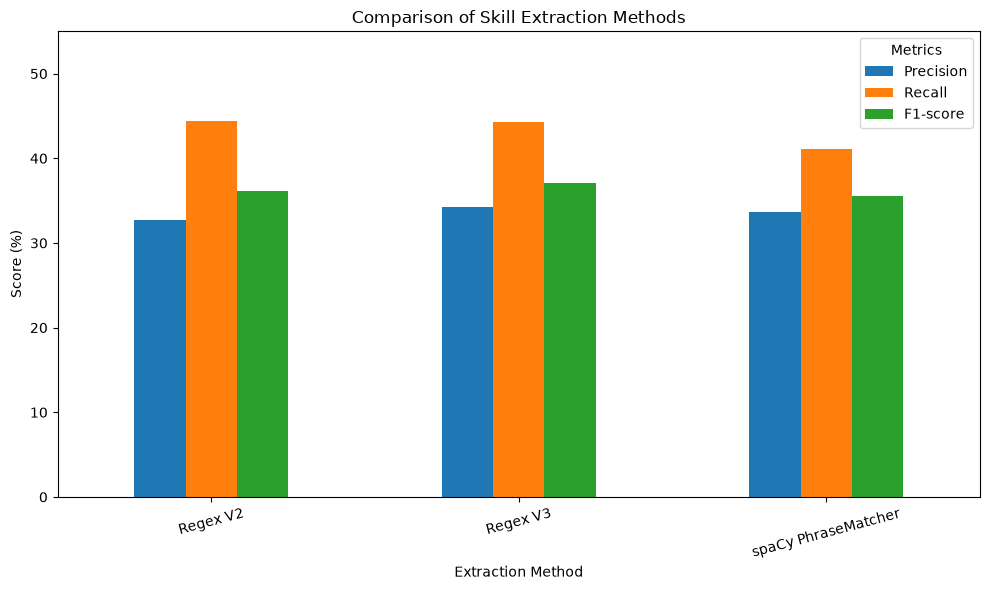

In [8]:
import matplotlib.pyplot as plt
import pandas as pd

comparison_df = pd.DataFrame({
    "Method": [
        "Regex V2",
        "Regex V3",
        "spaCy PhraseMatcher"
    ],
    "Precision": [32.71, 34.26, 33.66],
    "Recall": [44.42, 44.30, 41.11],
    "F1-score": [36.18, 37.12, 35.54]
})

comparison_df.plot(
    x="Method",
    y=["Precision", "Recall", "F1-score"],
    kind="bar",
    figsize=(10, 6)
)

plt.title("Comparison of Skill Extraction Methods")
plt.ylabel("Score (%)")
plt.xlabel("Extraction Method")
plt.xticks(rotation=15)
plt.ylim(0, 55)
plt.legend(title="Metrics")
plt.tight_layout()
plt.show()

In [9]:
from collections import Counter

false_positive_counter = Counter()

for predicted, actual in zip(spacy_predictions, actual_skill_sets):
    false_positives = predicted - actual
    false_positive_counter.update(false_positives)

top_false_positives = pd.DataFrame(
    false_positive_counter.most_common(20),
    columns=["Skill", "False Positive Count"]
)

display(top_false_positives)

,Skill,False Positive Count
0,management,492
1,training,357
2,sales,328
3,technology,315
4,compensation,313
5,finance,244
6,reporting,207
7,marketing,206
8,planning,187
9,applications,184


In [10]:
skill_to_inspect = "management"

examples = []

for i, (predicted, actual) in enumerate(
    zip(spacy_predictions, actual_skill_sets)
):
    if skill_to_inspect in predicted and skill_to_inspect not in actual:
        examples.append({
            "Job Title": df_clean.iloc[i]["job_title"],
            "Description": df_clean.iloc[i]["job_description"][:500],
            "Reference Skills": ", ".join(sorted(actual)[:10])
        })

display(pd.DataFrame(examples).head(5))

,Job Title,Description,Reference Skills
0,Human Resources Generalist (Hybrid Role),DESCRIPTION\n\n WHO WE ARE \n\nAVI-SPL IS A DI...,"attention to detail, change management, commun..."
1,Human Resources Manager,JOB DESCRIPTION: · THE HR MANAGER WILL SUPPORT...,"attention to detail, benefits administration, ..."
2,Human Resources Generalist,DRIVE YOUR FUTURE WITH TURN 14 DISTRIBUTION! N...,"attention to detail, benefits administration, ..."
3,Human Resources Information System Partner III,JOB OVERVIEW\n\nARE YOU A SYSTEM SETUP EXPERT ...,"business intelligence, cognos reporting, colla..."
4,Human Resources Specialist,GROUP MANAGEMENT SERVICES IS LOOKING FOR SELF ...,"autonomy, bachelor's degree, background checks..."


In [11]:
import re

skill_to_inspect = "management"
context_examples = []

for i, (predicted, actual) in enumerate(
    zip(spacy_predictions, actual_skill_sets)
):
    if skill_to_inspect in predicted and skill_to_inspect not in actual:

        description = df_clean.iloc[i]["job_description_clean"]

        matches = re.finditer(
            r"\bmanagement\b",
            description
        )

        for match in list(matches)[:2]:
            start = max(0, match.start() - 100)
            end = min(len(description), match.end() + 100)

            context_examples.append({
                "Job Title": df_clean.iloc[i]["job_title"],
                "Context": description[start:end]
            })

        if len(context_examples) >= 10:
            break

display(pd.DataFrame(context_examples))

,Job Title,Context
0,Human Resources Generalist (Hybrid Role),focused on supporting hr initiatives and stra...
1,Human Resources Generalist (Hybrid Role),development & change management. day-to-day re...
2,Human Resources Manager,roactively with all employees and functional a...
3,Human Resources Manager,onsibilities: general:a. proactively advise se...
4,Human Resources Generalist,ll levels in the warehouse to ensure productiv...
5,Human Resources Generalist,oductivity standards are consistently being me...
6,Human Resources Information System Partner III,nd approvals. you're a good fit if you have (o...
7,Human Resources Information System Partner III,effective communication and diplomacy skills t...
8,Human Resources Specialist,group management services is looking for self ...
9,Director of Human Resources,"ocedures to staff, ensuring that staff underst..."


In [12]:
from collections import Counter

false_negative_counter = Counter()

for predicted, actual in zip(spacy_predictions, actual_skill_sets):
    false_negatives = actual - predicted
    false_negative_counter.update(false_negatives)

top_false_negatives = pd.DataFrame(
    false_negative_counter.most_common(20),
    columns=["Skill", "False Negative Count"]
)

display(top_false_negatives)

,Skill,False Negative Count
0,problem solving,825
1,communication,727
2,adaptability,566
3,teamwork,516
4,relationship building,245
5,collaboration,238
6,data analysis,224
7,time management,223
8,interpersonal skills,183
9,organizational skills,166


In [13]:
skills_to_check = [
    "problem solving",
    "communication",
    "adaptability",
    "teamwork"
]

for skill in skills_to_check:
    labeled_jobs = df_clean[
        df_clean["skills_clean"].apply(lambda skills: skill in skills)
    ]

    exact_mentions = labeled_jobs[
        labeled_jobs["job_description_clean"].str.contains(
            re.escape(skill), regex=True, na=False
        )
    ]

    print(f"\nSkill: {skill}")
    print("Jobs with this reference label:", len(labeled_jobs))
    print("Descriptions containing exact phrase:", len(exact_mentions))
    print(
        "Exact phrase coverage:",
        f"{len(exact_mentions) / len(labeled_jobs) * 100:.2f}%"
    )


Skill: problem solving
Jobs with this reference label: 878
Descriptions containing exact phrase: 67
Exact phrase coverage: 7.63%

Skill: communication
Jobs with this reference label: 1092
Descriptions containing exact phrase: 716
Exact phrase coverage: 65.57%

Skill: adaptability
Jobs with this reference label: 588
Descriptions containing exact phrase: 30
Exact phrase coverage: 5.10%

Skill: teamwork
Jobs with this reference label: 569
Descriptions containing exact phrase: 59
Exact phrase coverage: 10.37%


In [14]:
skill = "problem solving"

examples = df_clean[
    df_clean["skills_clean"].apply(
        lambda skills: skill in skills
    )
    &
    ~df_clean["job_description_clean"].str.contains(
        r"\bproblem solving\b", regex=True, na=False
    )
]

for _, row in examples.head(5).iterrows():
    print("\nJOB TITLE:", row["job_title"])
    print("DESCRIPTION:")
    print(row["job_description"][:1000])
    print("-" * 80)


JOB TITLE: Human Resources Manager
DESCRIPTION:
BE PART OF A STELLAR TEAM AT YSB AS THE MANAGER OF HUMAN RESOURCES. JOIN US AS YSB ENTERS A NEW AND VIBRANT ERA WITH THE COMPLETION OF THE YSB CENTER FOR YOUTH SUCCESS THIS SUMMER. AS PART OF THE SENIOR LEADERSHIP TEAM AT YSB, THE HR MANAGER WILL DEVELOP, LEAD, AND COORDINATE ALL ACTIVITIES UNDER THE HUMAN RESOURCES UMBRELLA.
THIS ROLE IS RESPONSIBLE FOR PLANNING, DEVELOPING, LEADING, AND COORDINATING ALL ACTIVITIES UNDER THE HUMAN RESOURCES UMBRELLA INCLUDING BUT NOT LIMITED TO TALENT ACQUISITION, COMPENSATION AND BENEFIT STRUCTURE, EMPLOYEE EXPERIENCE, PERFORMANCE MANAGEMENT, AND POLICY. MUST HAVE A THOROUGH UNDERSTANDING OF FEDERAL AND STATE LEGAL COMPLIANCE.
DUTIES/RESPONSIBILITIES:COLLABORATE WITH LEADERSHIP TO IDENTIFY PROPER STAFFING LEVELS; CREATE A RECRUITMENT STRATEGY BY DEVELOPING AND EXECUTING BEST PRACTICES IN TALENT ACQUISITION.ENSURE ALL ON-BOARDING ACTIVITIES FOLLOW LEGAL AND ORGANIZATIONAL POLICY INCLUDING PRE-EMPLOYMENT

In [15]:
related_terms = [
    "resolve issues",
    "troubleshoot",
    "identify problems",
    "analyze problems",
    "make recommendations",
    "process improvements",
    "decision making",
    "critical thinking",
    "root cause",
    "solutions"
]

problem_solving_jobs = df_clean[
    df_clean["skills_clean"].apply(
        lambda skills: "problem solving" in skills
    )
]

for term in related_terms:
    count = problem_solving_jobs[
        problem_solving_jobs["job_description_clean"].str.contains(
            rf"\b{re.escape(term)}\b",
            regex=True,
            na=False
        )
    ].shape[0]

    print(f"{term}: {count}")

resolve issues: 20
troubleshoot: 28
identify problems: 5
analyze problems: 0
make recommendations: 30
process improvements: 31
decision making: 32
critical thinking: 28
root cause: 13
solutions: 358


In [16]:
alternative_pattern = (
    r"\b(resolve issues|troubleshoot|identify problems|"
    r"analyze problems|make recommendations|process improvements|"
    r"decision making|critical thinking|root cause|solutions)\b"
)

alternative_matches = problem_solving_jobs[
    problem_solving_jobs["job_description_clean"].str.contains(
        alternative_pattern,
        regex=True,
        na=False
    )
]

print("Jobs labelled with problem solving:", len(problem_solving_jobs))
print("Jobs containing at least one alternative:", len(alternative_matches))

coverage = len(alternative_matches) / len(problem_solving_jobs) * 100

print(f"Alternative expression coverage: {coverage:.2f}%")

Jobs labelled with problem solving: 878
Jobs containing at least one alternative: 442
Alternative expression coverage: 50.34%


C:\Users\user\AppData\Local\Temp\ipykernel_13848\1218400462.py:8: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  problem_solving_jobs["job_description_clean"].str.contains(


In [1]:
import pandas as pd
from pathlib import Path

dataset_path = Path("../data/raw/train-00000-of-00001 (1).parquet")

df = pd.read_parquet(dataset_path)

print("DATASET INFORMATION")
print("-------------------")
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 records:")
display(df.head())

print("\nData types:")
print(df.dtypes)

DATASET INFORMATION
-------------------
Dataset shape: (1167, 5)

Column names:
['job_id', 'category', 'job_title', 'job_description', 'job_skill_set']

First 5 records:


,job_id,category,job_title,job_description,job_skill_set
0,3902668440,HR,Sr Human Resource Generalist,SUMMARY\nTHE SR. HR GENERALIST PROVIDES HR EXP...,"['employee relations', 'talent acquisition', '..."
1,3905823748,HR,Human Resources Manager,BE PART OF A STELLAR TEAM AT YSB AS THE MANAGE...,"['Talent Acquisition', 'Employee Performance M..."
2,3905854799,HR,Director of Human Resources,OUR CLIENT IS A THRIVING ORGANIZATION OFFERING...,"['Human Resources Management', 'Recruitment', ..."
3,3905834061,HR,Chief Human Resources Officer,JOB TITLE: CHIEF HUMAN RESOURCES OFFICER (CHRO...,"['talent management', 'organizational developm..."
4,3906250451,HR,Human Resources Generalist (Hybrid Role),DESCRIPTION\n\n WHO WE ARE \n\nAVI-SPL IS A DI...,"['Microsoft Office', 'Data analysis', 'Employe..."



Data types:
job_id             int64
category             str
job_title            str
job_description      str
job_skill_set        str
dtype: object


In [2]:
print("JOB CATEGORY DISTRIBUTION")
print("-------------------------")

category_counts = df["category"].value_counts()

print(category_counts)

print("\nCategory percentages:")

category_percentages = (
    df["category"].value_counts(normalize=True) * 100
)

print(category_percentages.round(2))

JOB CATEGORY DISTRIBUTION
-------------------------
category
INFORMATION-TECHNOLOGY    240
BUSINESS-DEVELOPMENT      239
FINANCE                   236
SALES                     232
HR                        220
Name: count, dtype: int64

Category percentages:
category
INFORMATION-TECHNOLOGY    20.57
BUSINESS-DEVELOPMENT      20.48
FINANCE                   20.22
SALES                     19.88
HR                        18.85
Name: proportion, dtype: float64


In [3]:
print("DATA QUALITY CHECK")
print("------------------")

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nEmpty job descriptions:",
      df["job_description"].astype(str).str.strip().eq("").sum())

print("\nEmpty job titles:",
      df["job_title"].astype(str).str.strip().eq("").sum())


DATA QUALITY CHECK
------------------

Missing values:
job_id             0
category           0
job_title          0
job_description    0
job_skill_set      0
dtype: int64

Duplicate rows: 0

Empty job descriptions: 0

Empty job titles: 0


In [4]:
df["word_count"] = df["job_description"].astype(str).apply(
    lambda text: len(text.split())
)

print("JOB DESCRIPTION LENGTH")
print("----------------------")

print("Total job descriptions:", len(df))

print("Average words per description:",
      round(df["word_count"].mean(), 2))

print("Shortest description:",
      df["word_count"].min(), "words")

print("Longest description:",
      df["word_count"].max(), "words")

print("Median words per description:",
      df["word_count"].median())

JOB DESCRIPTION LENGTH
----------------------
Total job descriptions: 1167
Average words per description: 516.82
Shortest description: 29 words
Longest description: 1851 words
Median words per description: 471.0


In [5]:
from collections import Counter

all_words = []

for description in df["job_description"].astype(str):
    words = description.lower().split()
    all_words.extend(words)

word_counts = Counter(all_words)

total_tokens = len(all_words)
unique_types = len(word_counts)

print("VOCABULARY STATISTICS")
print("---------------------")

print("Total tokens:", total_tokens)
print("Unique types:", unique_types)
print("Vocabulary size:", unique_types)

print("\nTop 20 most frequent words:")

for word, count in word_counts.most_common(20):
    print(f"{word}: {count}")

VOCABULARY STATISTICS
---------------------
Total tokens: 603130
Unique types: 47002
Vocabulary size: 47002

Top 20 most frequent words:
and: 38340
to: 19175
the: 17148
of: 13560
a: 10361
in: 9998
with: 8986
for: 7058
is: 4566
or: 4562
our: 4204
as: 3892
business: 3465
on: 3229
we: 2964
are: 2866
will: 2819
be: 2747
an: 2635
experience: 2613


In [6]:
print("WORD FREQUENCY ANALYSIS")
print("-----------------------")

print("Words appearing only once:",
      sum(1 for count in word_counts.values() if count == 1))

print("Words appearing 5 times or fewer:",
      sum(1 for count in word_counts.values() if count <= 5))

print("Words appearing 10 times or fewer:",
      sum(1 for count in word_counts.values() if count <= 10))

print("\nTop 10 most frequent words:")

for word, count in word_counts.most_common(10):
    print(f"{word}: {count}")

WORD FREQUENCY ANALYSIS
-----------------------
Words appearing only once: 29267
Words appearing 5 times or fewer: 39926
Words appearing 10 times or fewer: 42469

Top 10 most frequent words:
and: 38340
to: 19175
the: 17148
of: 13560
a: 10361
in: 9998
with: 8986
for: 7058
is: 4566
or: 4562


In [7]:
print("MESSY TEXT EXAMPLES")
print("-------------------")

for i in range(5):
    print(f"\nExample {i + 1}")
    print("Job title:", df.iloc[i]["job_title"])
    print("Original description:")
    print(df.iloc[i]["job_description"][:800])
    print("-" * 70)

MESSY TEXT EXAMPLES
-------------------

Example 1
Job title: Sr Human Resource Generalist
Original description:
SUMMARY
THE SR. HR GENERALIST PROVIDES HR EXPERTISE ACROSS VARIOUS FUNCTIONS INCLUDING EMPLOYEE RELATIONS, TALENT ACQUISITION, PERFORMANCE MANAGEMENT, PAYROLL, COMPENSATION AND BENEFITS. THE SR. HR GENERALIST HAS RESPONSIBILITIES THAT ARE STRATEGIC, ADMINISTRATIVE, AND CONSULTATIVE. THIS ROLE PROVIDES CONSULTATIVE HR BUSINESS PARTNER SUPPORT TO ASSIGNED BUSINESS UNITS ACROSS ALL ASPECTS OF THE EMPLOYEE LIFE CYCLE. THIS ROLE ALSO SUPPORTS HR OPERATIONS WITH WEEKLY PAYROLL PROCESSING. THE SR. HR GENERALIST IS ALSO RESPONSIBLE FOR DEVELOPING AND IMPLEMENTING HR SOLUTIONS THAT ALIGN WITH THE COMPANY'S GOALS, ENSURING A HIGH LEVEL OF EMPLOYEE ENGAGEMENT, AND FOSTERING A POSITIVE AND INCLUSIVE WORKPLACE CULTURE.
KEY RESPONSIBILITIES:
· CONSULT WITH ASSIGNED BUSINESS PARTNERS ON ALL ASPECTS OF HR
----------------------------------------------------------------------

Example 2
Job 

In [8]:
import re

sample_text = df.iloc[0]["job_description"]

# Method 1: Whitespace tokenization
whitespace_tokens = sample_text.split()

# Method 2: Regular expression tokenization
regex_tokens = re.findall(r"\b[\w'-]+\b", sample_text)

print("TOKENIZATION COMPARISON")
print("-----------------------")

print("\nOriginal text (first 300 characters):")
print(sample_text[:300])

print("\nMethod 1: Whitespace Tokenization")
print("Total tokens:", len(whitespace_tokens))
print("First 20 tokens:", whitespace_tokens[:20])

print("\nMethod 2: Regex Tokenization")
print("Total tokens:", len(regex_tokens))
print("First 20 tokens:", regex_tokens[:20])


TOKENIZATION COMPARISON
-----------------------

Original text (first 300 characters):
SUMMARY
THE SR. HR GENERALIST PROVIDES HR EXPERTISE ACROSS VARIOUS FUNCTIONS INCLUDING EMPLOYEE RELATIONS, TALENT ACQUISITION, PERFORMANCE MANAGEMENT, PAYROLL, COMPENSATION AND BENEFITS. THE SR. HR GENERALIST HAS RESPONSIBILITIES THAT ARE STRATEGIC, ADMINISTRATIVE, AND CONSULTATIVE. THIS ROLE PROVID

Method 1: Whitespace Tokenization
Total tokens: 583
First 20 tokens: ['SUMMARY', 'THE', 'SR.', 'HR', 'GENERALIST', 'PROVIDES', 'HR', 'EXPERTISE', 'ACROSS', 'VARIOUS', 'FUNCTIONS', 'INCLUDING', 'EMPLOYEE', 'RELATIONS,', 'TALENT', 'ACQUISITION,', 'PERFORMANCE', 'MANAGEMENT,', 'PAYROLL,', 'COMPENSATION']

Method 2: Regex Tokenization
Total tokens: 584
First 20 tokens: ['SUMMARY', 'THE', 'SR', 'HR', 'GENERALIST', 'PROVIDES', 'HR', 'EXPERTISE', 'ACROSS', 'VARIOUS', 'FUNCTIONS', 'INCLUDING', 'EMPLOYEE', 'RELATIONS', 'TALENT', 'ACQUISITION', 'PERFORMANCE', 'MANAGEMENT', 'PAYROLL', 'COMPENSATION']


In [9]:
import re

sample_text = " ".join(df["job_description"].astype(str))

patterns = {
    "Email addresses": r"\b[\w.+-]+@[\w.-]+\.[A-Za-z]{2,}\b",
    "URLs": r"https?://\S+|www\.\S+",
    "Phone numbers": r"\b(?:\+?\d[\d\s().-]{7,}\d)\b"
}

print("REGULAR EXPRESSION TESTING")
print("--------------------------")

for name, pattern in patterns.items():
    matches = re.findall(pattern, sample_text, flags=re.IGNORECASE)
    print(f"\n{name}:")
    print("Number of matches:", len(matches))
    print("Examples:", matches[:5])

REGULAR EXPRESSION TESTING
--------------------------

Email addresses:
Number of matches: 152
Examples: ['HR.OPERATIONS@VISHAY.COM', 'CHRC511@KELLYSERVICES.COM', 'TALENT.MOBILITY@PRYSMIANGROUP.COM', 'CAREERS@RPI.EDU', 'RECRUITING-ACCOMMODATIONS@HOLCIM.COM']

URLs:
Number of matches: 233
Examples: ['WWW.GROUPMGMT.COM', 'WWW.DCHR.DC.GOV.)COMPLIMENTARY', 'WWW.COVLIVING.ORG', 'WWW.COVENANTCAREATHOME.ORG.', 'WWW.VISHAY.COM.']

Phone numbers:
Number of matches: 107
Examples: ['888) 487-8850', '773) 355-4557', '610-484 2192', '202-292-2542', '205-484-9467']


In [10]:
print("DATA-SPECIFIC TEXT CHALLENGES")
print("-----------------------------")

descriptions = df["job_description"].dropna().astype(str)

uppercase_count = sum(
    text == text.upper() and any(char.isalpha() for char in text)
    for text in descriptions
)

bullet_count = sum(
    any(symbol in text for symbol in ["·", "•", "▪", "►"])
    for text in descriptions
)

markdown_count = sum(
    any(symbol in text for symbol in ["**", "__", "##"])
    for text in descriptions
)

print("Descriptions written entirely in uppercase:", uppercase_count)
print("Descriptions containing bullet symbols:", bullet_count)
print("Descriptions containing Markdown formatting:", markdown_count)

DATA-SPECIFIC TEXT CHALLENGES
-----------------------------
Descriptions written entirely in uppercase: 1167
Descriptions containing bullet symbols: 91
Descriptions containing Markdown formatting: 40


In [11]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

print("STOP WORD ANALYSIS")
print("------------------")

print("Total English stop words:", len(ENGLISH_STOP_WORDS))

sample_description = df.iloc[0]["job_description"].lower()
sample_words = sample_description.split()

stopword_count = sum(
    word.strip(".,:;!?()") in ENGLISH_STOP_WORDS
    for word in sample_words
)

print("Words in first description:", len(sample_words))
print("Stop words in first description:", stopword_count)

print("\nExamples of stop words:")
print(list(ENGLISH_STOP_WORDS)[:20])

STOP WORD ANALYSIS
------------------
Total English stop words: 318
Words in first description: 583
Stop words in first description: 178

Examples of stop words:
['someone', 'side', 'move', 'where', 'me', 'so', 'must', 'eleven', 'an', 'therein', 'nobody', 'sixty', 'yet', 'below', 'becoming', 'never', 'nor', 'than', 'these', 'even']


In [13]:
%pip install nltk

   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ------ --------------------------------- 0.3/1.7 MB ? eta -:--:--
   ------------ --------------------------- 0.5/1.7 MB 1.2 MB/s eta 0:00:02
   ------------------------------------ --- 1.6/1.7 MB 2.5 MB/s eta 0:00:01
   ---------------------------------------- 1.7/1.7 MB 2.5 MB/s  0:00:01
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [14]:
import nltk
print("NLTK version:", nltk.__version__)


NLTK version: 3.10.4


In [15]:
import spacy
from nltk.stem import PorterStemmer

stemmer = PorterStemmer()
nlp = spacy.load("en_core_web_sm")

sample_words = [
    "managing",
    "management",
    "employees",
    "recruitment",
    "developing",
    "responsibilities",
    "analyzing",
    "benefits"
]

print("STEMMING VS LEMMATIZATION")
print("-------------------------")

doc = nlp(" ".join(sample_words))

for original, token in zip(sample_words, doc):
    print(
        f"{original:20} "
        f"Stem: {stemmer.stem(original):15} "
        f"Lemma: {token.lemma_}"
    )

STEMMING VS LEMMATIZATION
-------------------------
managing             Stem: manag           Lemma: manage
management           Stem: manag           Lemma: management
employees            Stem: employe         Lemma: employee
recruitment          Stem: recruit         Lemma: recruitment
developing           Stem: develop         Lemma: develop
responsibilities     Stem: respons         Lemma: responsibility
analyzing            Stem: analyz          Lemma: analyze
benefits             Stem: benefit         Lemma: benefit


In [16]:
import re
import unicodedata
import pandas as pd
import spacy

nlp = spacy.load("en_core_web_sm")

def clean_job_description(text):

    if pd.isna(text):
        return ""

    # 1. Unicode normalization
    text = unicodedata.normalize("NFKC", str(text))

    # 2. Convert text to lowercase
    text = text.casefold()

    # 3. Remove email addresses
    text = re.sub(
        r"\b[\w.+-]+@[\w.-]+\.[A-Za-z]{2,}\b",
        " ",
        text
    )

    # 4. Remove URLs
    text = re.sub(
        r"https?://\S+|www\.\S+",
        " ",
        text,
        flags=re.IGNORECASE
    )

    # 5. Remove phone numbers
    text = re.sub(
        r"\b(?:\+?\d[\d\s().-]{7,}\d)\b",
        " ",
        text
    )

    # 6. Remove Markdown formatting
    text = re.sub(r"[*_`#~]+", " ", text)

    # 7. Remove bullet symbols
    text = re.sub(r"[·•▪►]", " ", text)

    # 8. Normalize whitespace
    text = re.sub(r"\s+", " ", text).strip()

    # 9. Apply lemmatization while preserving stop words
    doc = nlp(text)

    cleaned_tokens = []

    for token in doc:

        if token.is_space or token.is_punct:
            continue

        if token.is_alpha:
            cleaned_tokens.append(token.lemma_.casefold())

        elif token.like_num:
            cleaned_tokens.append(token.text)

        elif any(char.isalnum() for char in token.text):
            cleaned_tokens.append(token.text.casefold())

    return " ".join(cleaned_tokens)


print("Cleaning function created successfully.")

Cleaning function created successfully.


In [17]:
original_text = df.iloc[0]["job_description"]

cleaned_text = clean_job_description(original_text)

print("ORIGINAL TEXT")
print("-------------")
print(original_text[:800])

print("\nCLEANED TEXT")
print("------------")
print(cleaned_text[:800])

ORIGINAL TEXT
-------------
SUMMARY
THE SR. HR GENERALIST PROVIDES HR EXPERTISE ACROSS VARIOUS FUNCTIONS INCLUDING EMPLOYEE RELATIONS, TALENT ACQUISITION, PERFORMANCE MANAGEMENT, PAYROLL, COMPENSATION AND BENEFITS. THE SR. HR GENERALIST HAS RESPONSIBILITIES THAT ARE STRATEGIC, ADMINISTRATIVE, AND CONSULTATIVE. THIS ROLE PROVIDES CONSULTATIVE HR BUSINESS PARTNER SUPPORT TO ASSIGNED BUSINESS UNITS ACROSS ALL ASPECTS OF THE EMPLOYEE LIFE CYCLE. THIS ROLE ALSO SUPPORTS HR OPERATIONS WITH WEEKLY PAYROLL PROCESSING. THE SR. HR GENERALIST IS ALSO RESPONSIBLE FOR DEVELOPING AND IMPLEMENTING HR SOLUTIONS THAT ALIGN WITH THE COMPANY'S GOALS, ENSURING A HIGH LEVEL OF EMPLOYEE ENGAGEMENT, AND FOSTERING A POSITIVE AND INCLUSIVE WORKPLACE CULTURE.
KEY RESPONSIBILITIES:
· CONSULT WITH ASSIGNED BUSINESS PARTNERS ON ALL ASPECTS OF HR

CLEANED TEXT
------------
summary the sr hr generalist provide hr expertise across various function include employee relation talent acquisition performance management pa

In [20]:

import re
import unicodedata
import pandas as pd
import spacy

nlp = spacy.load("en_core_web_sm")

def clean_job_description(text):

    if pd.isna(text):
        return ""

    # 1. Unicode normalization
    text = unicodedata.normalize("NFKC", str(text))

    # 2. Convert text to lowercase
    text = text.casefold()

    # 3. Remove email addresses
    text = re.sub(
        r"\b[\w.+-]+@[\w.-]+\.[a-z]{2,}\b",
        " ",
        text
    )

    # 4. Remove URLs
    text = re.sub(
        r"https?://\S+|www\.\S+",
        " ",
        text
    )

    # 5. Remove phone numbers
    text = re.sub(
        r"\b(?:\+?\d[\d\s().-]{7,}\d)\b",
        " ",
        text
    )

    # 6. Remove Markdown formatting
    text = re.sub(r"[*_`#~]+", " ", text)

    # 7. Remove bullet symbols
    text = re.sub(r"[·•▪►]", " ", text)

    # 8. Normalize whitespace
    text = re.sub(r"\s+", " ", text).strip()

    # 9. Apply spaCy lemmatization
    doc = nlp(text)

    cleaned_tokens = []

    for token in doc:

        if token.is_space or token.is_punct:
            continue

        if token.is_alpha:
            cleaned_tokens.append(token.lemma_.casefold())

        elif token.like_num:
            cleaned_tokens.append(token.text)

        elif any(char.isalnum() for char in token.text):
            cleaned_tokens.append(token.text.casefold())

    # 10. Join tokens
    result = " ".join(cleaned_tokens)

    # 11. Fix possessive endings
    result = re.sub(r"\s+'s\b", "'s", result)

    return result


print("Text-cleaning function created successfully.")


Text-cleaning function created successfully.


In [22]:
cleaned_text = clean_job_description(df.iloc[0]["job_description"])

print("UPDATED CLEANED TEXT")
print("--------------------")
print(cleaned_text[:800])

UPDATED CLEANED TEXT
--------------------
summary the sr hr generalist provide hr expertise across various function include employee relation talent acquisition performance management payroll compensation and benefit the sr hr generalist have responsibility that be strategic administrative and consultative this role provide consultative hr business partner support to assign business unit across all aspect of the employee life cycle this role also support hr operation with weekly payroll processing the sr hr generalist be also responsible for develop and implement hr solution that align with the company's goal ensure a high level of employee engagement and foster a positive and inclusive workplace culture key responsibility consult with assign business partner on all aspect of hr facilitate and communicate organizational policy and


In [23]:

# Create a copy of the original dataset
df_cleaned = df.copy()

# Apply the cleaning function to every job description
df_cleaned["cleaned_description"] = df_cleaned[
    "job_description"
].apply(clean_job_description)

# Display results
print("FULL DATASET CLEANING")
print("---------------------")

print("Original records:", len(df))
print("Cleaned records:", len(df_cleaned))

print("\nOriginal description:")
print(df_cleaned.iloc[0]["job_description"][:300])

print("\nCleaned description:")
print(df_cleaned.iloc[0]["cleaned_description"][:300])

print("\nMissing cleaned descriptions:",
      df_cleaned["cleaned_description"].isna().sum())

print("\nEmpty cleaned descriptions:",
      df_cleaned["cleaned_description"].str.strip().eq("").sum())


FULL DATASET CLEANING
---------------------
Original records: 1167
Cleaned records: 1167

Original description:
SUMMARY
THE SR. HR GENERALIST PROVIDES HR EXPERTISE ACROSS VARIOUS FUNCTIONS INCLUDING EMPLOYEE RELATIONS, TALENT ACQUISITION, PERFORMANCE MANAGEMENT, PAYROLL, COMPENSATION AND BENEFITS. THE SR. HR GENERALIST HAS RESPONSIBILITIES THAT ARE STRATEGIC, ADMINISTRATIVE, AND CONSULTATIVE. THIS ROLE PROVID

Cleaned description:
summary the sr hr generalist provide hr expertise across various function include employee relation talent acquisition performance management payroll compensation and benefit the sr hr generalist have responsibility that be strategic administrative and consultative this role provide consultative hr 

Missing cleaned descriptions: 0

Empty cleaned descriptions: 0


In [24]:

from collections import Counter

# Original vocabulary
original_words = []

for description in df["job_description"].astype(str):
    original_words.extend(description.lower().split())

# Cleaned vocabulary
cleaned_words = []

for description in df_cleaned["cleaned_description"]:
    cleaned_words.extend(description.split())

# Calculate statistics
original_vocabulary = set(original_words)
cleaned_vocabulary = set(cleaned_words)

original_tokens = len(original_words)
cleaned_tokens = len(cleaned_words)

original_vocab_size = len(original_vocabulary)
cleaned_vocab_size = len(cleaned_vocabulary)

vocab_reduction = (
    (original_vocab_size - cleaned_vocab_size)
    / original_vocab_size
) * 100

print("BEFORE AND AFTER CLEANING")
print("-------------------------")

print("Original total tokens:", original_tokens)
print("Cleaned total tokens:", cleaned_tokens)

print("\nOriginal vocabulary size:", original_vocab_size)
print("Cleaned vocabulary size:", cleaned_vocab_size)

print("\nVocabulary reduction:",
      round(vocab_reduction, 2), "%")


BEFORE AND AFTER CLEANING
-------------------------
Original total tokens: 603130
Cleaned total tokens: 613180

Original vocabulary size: 47002
Cleaned vocabulary size: 26485

Vocabulary reduction: 43.65 %


In [25]:

# Count original tokens using spaCy
original_spacy_tokens = 0

for description in df["job_description"].astype(str):
    doc = nlp(description)
    original_spacy_tokens += sum(
        1 for token in doc
        if not token.is_space and not token.is_punct
    )

# Count cleaned tokens
cleaned_spacy_tokens = sum(
    len(description.split())
    for description in df_cleaned["cleaned_description"]
)

print("TOKEN COUNT VERIFICATION")
print("------------------------")

print("Original tokens (spaCy):", original_spacy_tokens)
print("Cleaned tokens:", cleaned_spacy_tokens)

print("Difference:",
      cleaned_spacy_tokens - original_spacy_tokens)


TOKEN COUNT VERIFICATION
------------------------
Original tokens (spaCy): 617084
Cleaned tokens: 613180
Difference: -3904


In [26]:

from pathlib import Path

# Create processed data folder if it does not exist
processed_folder = Path("../data/processed")
processed_folder.mkdir(parents=True, exist_ok=True)

# Save cleaned dataset
output_path = processed_folder / "cleaned_job_skill_dataset.parquet"

df_cleaned.to_parquet(output_path, index=False)

print("CLEANED DATASET SAVED")
print("---------------------")
print("File:", output_path)
print("Records saved:", len(df_cleaned))
print("File exists:", output_path.exists())


CLEANED DATASET SAVED
---------------------
File: ..\data\processed\cleaned_job_skill_dataset.parquet
Records saved: 1167
File exists: True


In [27]:

# Load the saved cleaned dataset
df_verified = pd.read_parquet(output_path)

print("SAVED DATASET VERIFICATION")
print("--------------------------")

print("Dataset shape:", df_verified.shape)

print("\nColumns:")
print(df_verified.columns.tolist())

print("\nFirst cleaned description:")
print(df_verified["cleaned_description"].iloc[0][:500])

print("\nMissing cleaned descriptions:",
      df_verified["cleaned_description"].isna().sum())

print("\nOriginal and verified record counts match:",
      len(df_verified) == len(df))


SAVED DATASET VERIFICATION
--------------------------
Dataset shape: (1167, 7)

Columns:
['job_id', 'category', 'job_title', 'job_description', 'job_skill_set', 'word_count', 'cleaned_description']

First cleaned description:
summary the sr hr generalist provide hr expertise across various function include employee relation talent acquisition performance management payroll compensation and benefit the sr hr generalist have responsibility that be strategic administrative and consultative this role provide consultative hr business partner support to assign business unit across all aspect of the employee life cycle this role also support hr operation with weekly payroll processing the sr hr generalist be also responsibl

Missing cleaned descriptions: 0

Original and verified record counts match: True


In [28]:

import re
import unicodedata
import pandas as pd
import spacy


# Load the English language model
nlp = spacy.load("en_core_web_sm")


def clean_job_description(text):
    """Clean and normalize a job description."""

    if pd.isna(text):
        return ""

    # Unicode normalization
    text = unicodedata.normalize("NFKC", str(text))

    # Convert to lowercase
    text = text.casefold()

    # Remove email addresses
    text = re.sub(
        r"\b[\w.+-]+@[\w.-]+\.[a-z]{2,}\b",
        " ",
        text
    )

    # Remove URLs
    text = re.sub(
        r"https?://\S+|www\.\S+",
        " ",
        text
    )

    # Remove phone numbers
    text = re.sub(
        r"\b(?:\+?\d[\d\s().-]{7,}\d)\b",
        " ",
        text
    )

    # Remove Markdown formatting
    text = re.sub(r"[*_`#~]+", " ", text)

    # Remove bullet symbols
    text = re.sub(r"[·•▪►]", " ", text)

    # Normalize whitespace
    text = re.sub(r"\s+", " ", text).strip()

    # Apply lemmatization
    doc = nlp(text)

    cleaned_tokens = []

    for token in doc:

        if token.is_space or token.is_punct:
            continue

        if token.is_alpha:
            cleaned_tokens.append(token.lemma_.casefold())

        elif token.like_num:
            cleaned_tokens.append(token.text)

        elif any(char.isalnum() for char in token.text):
            cleaned_tokens.append(token.text.casefold())

    # Join tokens
    result = " ".join(cleaned_tokens)

    # Fix possessive endings
    result = re.sub(r"\s+'s\b", "'s", result)

    return result


if __name__ == "__main__":
    sample = "THE COMPANY'S EMPLOYEES ARE DEVELOPING NEW HR SOLUTIONS."

    print("Original:", sample)
    print("Cleaned:", clean_job_description(sample))


Original: THE COMPANY'S EMPLOYEES ARE DEVELOPING NEW HR SOLUTIONS.
Cleaned: the company's employee be develop new hr solution
